# Galaxies

Fünf Blicke auf Galaxien, jeweils mit echten Daten: die hellsten Galaxien auf einer Himmelskarte und das Licht von M 51 vom Röntgen- bis zum Radiobereich bis zur Zerlegung in Bulge und Scheibe, die Spektren von M 51 und die Gaswolken in M 101 mit Dichte, Staub und Sauerstoff, die Rotationskurven von 175 Galaxien und ihre Dunkle Materie, die Verbiegung von Scheiben in Kantenlage und der Schatten des schwarzen Lochs in M 87 aus den Daten des Event Horizon Telescope. Die Daten kommen aus SIMBAD, NED, SkyView, SDSS, VizieR, SPARC, den DESI Legacy Surveys und vom EHT; Downloads landen in `data/galaxies/`. Der Code steht in [`code/galaxies/`](https://github.com/deltorobarba/science/tree/main/code/galaxies), ein Modul je Teil (`photometry.py`, `hiiregions.py`, `rotation.py`, `warps.py`, `m87.py`, dazu `galdata.py` für den Cache und für Ersatzwege, wenn die Dienste in Straßburg ausfallen, und `overview.py` mit den Hilfsmodulen `catalog.py` für SIMBAD, `surveys.py` für SkyView, `plotting.py` für Karte und Bilder und `spectra.py` für SDSS); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Eine Galaxie besteht aus Sternen, Gas, Staub, Dunkler Materie und einem schwarzen Loch in der Mitte. Die fünf Teile nehmen sie auseinander, jedes Mal mit einer anderen Art von Messung.

- **Schritte 1 bis 12, Licht:** Eine Himmelskarte zeigt, wo die hellen Galaxien liegen. Bilder von M 51 vom Röntgen- bis zum Radiobereich zeigen, wo alte und junge Sterne sitzen; das Profil zerlegt die Galaxie in Bulge und Scheibe.
- **Schritte 13 bis 20, Gas:** Spektren in M 51 trennen Sternlicht, leuchtendes Gas und einen schwach aktiven Kern; die H-II-Regionen in M 101 geben Dichte, Staub, Ionisationsquelle und den Sauerstoff, der nach außen abnimmt.
- **Schritte 21 bis 27, Bewegung:** Rotationskurven von 147 Galaxien wiegen die Dunkle Materie, und eine einzige Beschleunigung koppelt sie an die sichtbare.
- **Schritte 28 bis 35, Form:** Scheiben in Kantenlage sind außen oft verbogen; drei Bänder trennen Geometrie von Staub.
- **Schritte 36 bis 42, Zentrum:** Aus 21 Basislinien des Event Horizon Telescope folgen Ring, Bild und Masse des schwarzen Lochs in M 87.

Die gemeinsame Lehre: Fast jede Größe kommt aus einem Verhältnis. Farben trennen junge von alten Sternen, Linienverhältnisse geben Dichte und Sauerstoff, Geschwindigkeit gegen Radius die Masse, und die Lage einer Nullstelle in der Fourier-Ebene den Durchmesser eines Rings, der kleiner ist als die Auflösung.

In [1]:
import sys
import subprocess
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "galaxies"
if "google.colab" in sys.modules:                            # in Colab: Pakete installieren, Code aus dem Repository holen
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)
    if not CODE.exists():
        CODE.mkdir(parents=True)
        for f in ["galdata.py", "photometry.py", "overview.py", "hiiregions.py", "rotation.py", "warps.py", "m87.py", "catalog.py", "surveys.py", "plotting.py", "spectra.py"]:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/galaxies/{f}", CODE / f)
elif importlib.util.find_spec("astroquery") is None:
    raise ImportError("Es fehlt eines der Pakete astroquery; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import photometry, overview, hiiregions, rotation, warps, m87

SIMBAD in Straßburg nicht erreichbar: Spiegel simbad.harvard.edu


**1. Photometrie: die hellsten Galaxien am Himmel**

Von den meisten Galaxien bekommt man nur ihr Licht, und schon das Bild in mehreren Wellenlängen verrät viel: Größe, Helligkeit, wo die alten Sterne sitzen, die die Masse tragen, und wo neue entstehen. Ein runder Bulge entsteht vor allem bei Verschmelzungen, eine flache Scheibe aus Gas, das ruhig nach innen strömt. Am Beispiel der Whirlpool-Galaxie M 51 wird das hier durchgerechnet; zuerst werden die hellsten Galaxien aus SIMBAD geholt.

Heller als V = 10.5 und größer als 3′ sind 129 Galaxien. An der Spitze stehen die beiden Magellanschen Wolken, Begleiter der Milchstraße, dann M 31 (200′, über sechsmal so groß wie der Vollmond) und M 33. Viele helle nahe Galaxien haben einen schwach aktiven Kern. Einige Einträge zeigen Grenzen des Katalogs, etwa B − V = 9.9 für NGC 6822.

In [2]:
photometry.brightest()

129 Galaxien mit V < 10.5 und Durchmesser >= 3.0' in SIMBAD

Häufigste Objekttypen: {'GtowardsGroup': 23, 'Seyfert2': 21, 'LINER': 16, 'GinPair': 11, 'EmissionG': 10, 'AGN': 8}

Die 15 hellsten:
            Name           Typ Hubble-Typ    V  B-V  Durchmesser [']  v [km/s]
        NAME LMC        Galaxy     SB(s)m 0.40  NaN       322.829987    262.20
        NAME SMC        Galaxy       dIrr 2.20 0.59       158.110001    145.60
            M 31           AGN     SA(s)b 3.44 0.92       199.529999   -300.00
            M 33 GtowardsGroup    SA(s)cd 5.72 0.55        60.259998   -179.20
NAME Centaurus A         BLLac      S0pec 6.84 1.34        25.700001    562.17
            M 81      Seyfert2         SA 6.94 0.95        21.379999    -47.00
   MCG-06-07-001        Galaxy       dSph 7.40 1.62        27.500000     54.70
            M 83    StarburstG    SAB(s)c 7.52 0.59        13.800000    519.10
           M 101       GinPair       S_AB 7.86 0.60        21.879999    243.03
          NGC 5

**2. Die hellsten Galaxien und die Messier-Objekte am Himmel**

Dieselben Galaxien als Himmelskarte in galaktischen Koordinaten (Mollweide-Projektion): Die Ebene der Milchstraße ist die Mittellinie, ihr Zentrum liegt in der Mitte. Dazu kommen die Nebel und Sternhaufen des Messier-Katalogs, den Charles Messier im 18. Jahrhundert anlegte, damit man die verwaschenen Flecken des Nordhimmels nicht mit Kometen verwechselt; die Ausgabe listet die Galaxien darunter. Abfragen und Karte kommen aus `catalog.py` und `plotting.py`.

Die Galaxien meiden einen Streifen entlang der Milchstraße, weil ihr Staub dort den Blick nach draußen verdeckt (Zone of Avoidance). Die Nebel liegen dagegen fast alle in diesem Streifen, denn sie gehören zur Milchstraße; Ausnahmen sind planetarische Nebel wie M 97, die aus alten Sternen entstehen. Die größten Punkte sind die beiden Magellanschen Wolken weit im Süden, dann M 31 und M 33.

110 Messier-Objekte: 56 Sternhaufen, 40 Galaxien, 12 Nebel, 2 sonstige
In Klammern der SIMBAD-Typ und die Größe (große Achse in Bogenminuten).

Galaxien (40):
  M 31 (AGN, 200′), M 32 (GiG, 3′), M 33 (GiG, 60′), M 49 (Sy2, 8′), M 51 (Sy2, 9′), M 58 (Sy2, 6′), M 59
  (GiG, 6′), M 60 (GiC, 6′), M 61 (Sy2, 5′), M 63 (LIN, 13′), M 64 (SyG, 11′), M 65 (GiP, 16′), M 66 (AGN,
  11′), M 74 (G, 7′), M 77 (Sy2, 5′), M 81 (Sy2, 21′), M 82 (AGN), M 83 (SBG, 14′), M 84 (Sy2, 6′), M 85 (GiP,
  7′), M 86 (GiG, 9′), M 87 (AGN, 6′), M 88 (Sy2, 7′), M 89 (Sy2, 4′), M 90 (Sy2, 10′), M 91 (LIN, 5′), M 94
  (SyG, 7′), M 95 (GiP, 6′), M 96 (GiP, 7′), M 98 (LIN, 11′), M 99 (H2G, 5′), M 100 (AGN, 6′), M 101 (GiP,
  22′), M 102 (SyG, 6′), M 104 (LIN, 9′), M 105 (LIN, 5′), M 106 (Sy2, 18′), M 108 (AGN, 15′), M 109 (GiG,
  8′), M 110 (GiG, 3′)


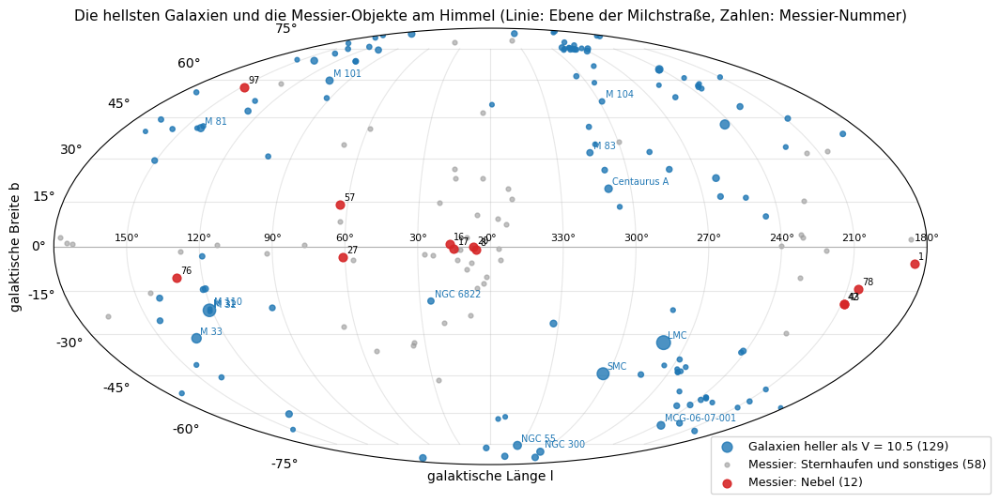

In [3]:
overview.sky_map()

**3. Die Galaxie und ihre Entfernung**

Aus SIMBAD kommen alle veröffentlichten Entfernungen außer denen aus der Rotverschiebung, ihr Median ist die Entfernung; aus NED die Fluchtgeschwindigkeit. Daraus folgen Maßstab, Durchmesser und absolute Helligkeit.

M 51 steht 7.85 Mpc entfernt (Median aus sechs Messungen zwischen 6.2 und 8.4 Mpc), also ist 1′ = 2.28 kpc, der Durchmesser 20.7 kpc (zwei Drittel der Milchstraße) und M_V = −21.1. Das Hubble-Gesetz gäbe 8.57 Mpc. Schon die Fluchtgeschwindigkeit unterscheidet sich zwischen NED und SIMBAD um 77 km/s: Bei so nahen Galaxien ist das Hubble-Gesetz als Entfernungsmaß unsicher.

Galaxie:               M 51   (NED: MESSIER 051, Typ GPair)
Objekttyp:             Seyfert2   |   Hubble-Typ: SA
Koordinaten:           13h29m52.7s +47d11m42.9s
Helligkeit:            V = 8.36   B-V = 0.90   K = 5.50
Scheinbare Größe:      9.0' x 7.8'   (PA 28°)
Fluchtgeschwindigkeit: 600 km/s (NED; SIMBAD: 523 km/s)
Entfernung:            7.85 Mpc = 25.6 Millionen Lichtjahre (Median aus 6 Messungen ohne Rotverschiebung)
Maßstab:               1' = 2.28 kpc
Durchmesser:           20.7 kpc = 67,355 Lichtjahre
Absolute Helligkeit:   M_V = -21.11

Hubble-Gesetz: v/H0 = 8.57 Mpc gegen die Entfernungsleiter 7.85 Mpc
Eigenbewegung: v - H0·D = +50 km/s


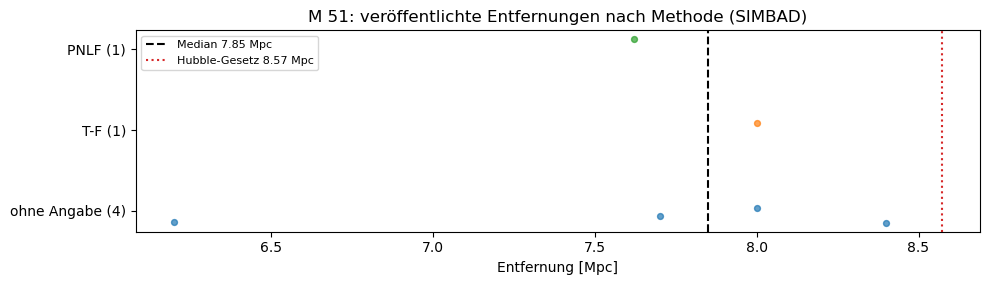

In [4]:
photometry.target()

**4. Bilder in sechs Wellenlängenbereichen**

SkyView liefert sechs Bilder auf demselben Raster, vom Ultraviolett (GALEX) über das Optische (DSS2) bis 12 µm (WISE). Die Ellipse ist die Größe laut SIMBAD.

Im UV leuchten nur die Spiralarme mit ihren jungen Sternhaufen; der Begleiter NGC 5195 ist fast unsichtbar, weil dort kaum Sterne entstehen. Optisch sieht man Sternlicht mit Staubbändern, im nahen Infrarot eine glatte Galaxie aus alten Sternen, in der NGC 5195 fast so hell ist wie der Kern von M 51. Bei 12 µm zeichnet warmer Staub wieder die Arme nach, weil junge Sterne ihn heizen.

Lade 6 Bilder, 400x400 Pixel, Feld 14.5 arcmin ...


   GALEX Near UV  (400, 400)
   DSS2 Blue      (400, 400)
   DSS2 Red       (400, 400)
   2MASS-K        (400, 400)
   WISE 3.4       (400, 400)
   WISE 12        (400, 400)
Pixelgröße 2.17"


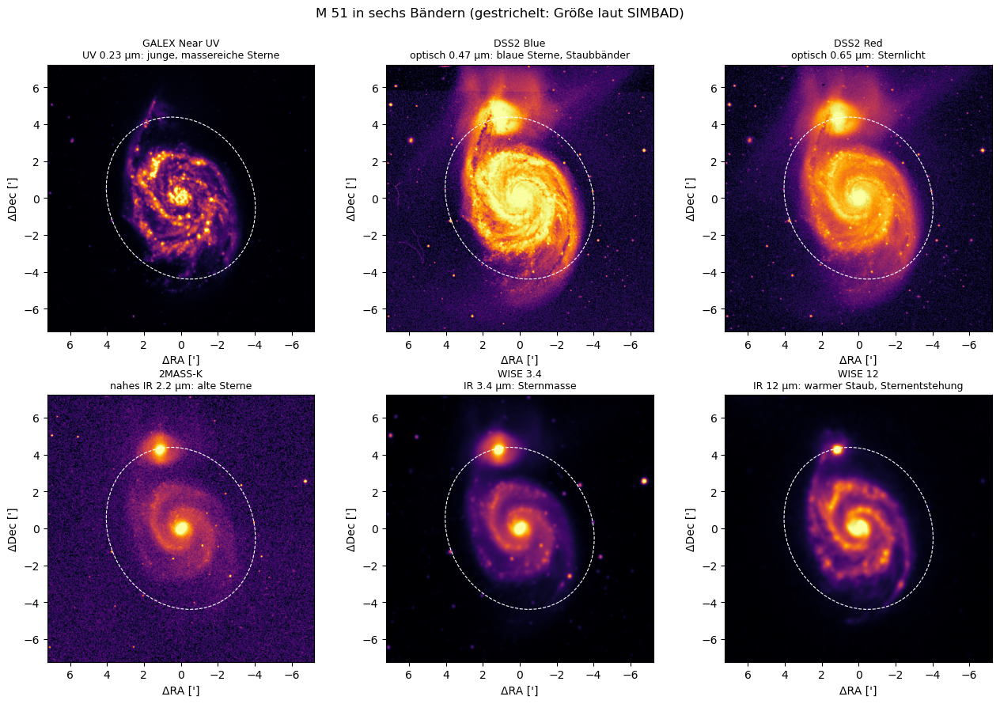

In [5]:
photometry.band_images()

**5. Farbbilder**

Links das optische Farbbild des Digitized Sky Survey, rechts ein Falschfarbenbild: Rot ist warmer Staub (12 µm), Grün sind alte Sterne (3.4 µm), Blau junge Sterne (UV). Ist der Dienst hips2fits des CDS nicht erreichbar (wie am 2026-11-13), wird das optische Bild aus den SkyView-Bildern DSS2 Rot und Blau zusammengesetzt.

Optisch sind die Arme blau mit hellen Sternhaufen, der Kern gelblich, an der Innenseite der Arme liegen dunkle Staubbänder. Im Falschfarbenbild leuchten die Arme blau-violett, wo junge Sterne und warmer Staub zusammenfallen; der Kern ist weiß, weil alle drei Bänder hell sind. NGC 5195 ist grün: nur alte Sterne, kein Staub, keine Sternentstehung.

hips2fits (CDS) nicht erreichbar: Farbbild aus SkyView DSS2 Rot und Blau


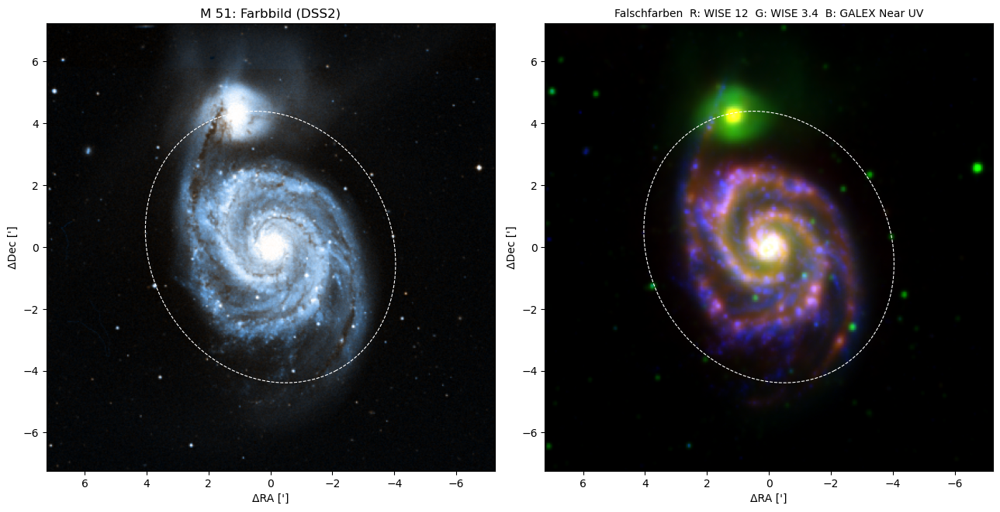

In [6]:
photometry.composites()

**6. Farbbilder im nahen und mittleren Infrarot**

Zwei weitere Mischungen zu den Bildern aus Schritt 5: nahes Infrarot aus 2MASS (K, H und J als Rot, Grün und Blau) und mittleres Infrarot aus WISE (12, 4.6 und 3.4 µm). SkyView rechnet jedes Band auf dasselbe Pixelgitter, deshalb passen sie ohne Ausrichtung aufeinander; jedes Band wird für sich mit einer Asinh-Kurve gestreckt, damit schwacher Rand und heller Kern zugleich sichtbar sind.

Im nahen Infrarot sind Staubbänder und blaue Sternhaufen verschwunden; es bleiben die alten Sterne, die den Kern und den Begleiter NGC 5195 am hellsten machen. Im mittleren Infrarot leuchten die Arme rötlich vom warmen Staub, den junge Sterne heizen; NGC 5195 und die Vordergrundsterne erscheinen türkis, weil bei ihnen das Sternlicht bei 3.4 und 4.6 µm überwiegt und warmer Staub fehlt.

6 Bilder, 14.5′ mit 600 Pixeln


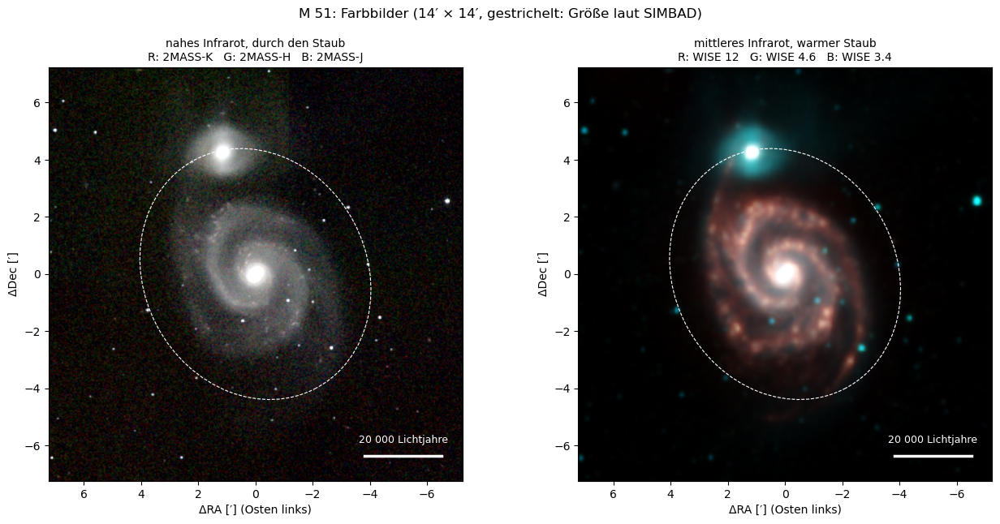

In [7]:
overview.ir_composites()

**7. M 51 vom Röntgen- bis zum Radiobereich**

Neun Durchmusterungen vom Röntgenbereich (ROSAT) bis 21 cm (NVSS) in einem Feld von 1°. Viele dieser Karten lösen nur Bogenminuten auf (Hα 6′, IRIS 4′, Planck bei 30 GHz 32′), im engen Feld der übrigen Bilder wäre M 51 dort nur ein Fleck; das größere Feld zeigt dafür die Umgebung. Die Hα-Karte ist aus mehreren Durchmusterungen der Milchstraße zusammengesetzt.

M 51 ist im Röntgenbereich, bei 100 µm, 350 µm und 21 cm ein Fleck in der Mitte, bei 22 µm und im Optischen noch eine Spirale. In der Hα-Karte und bei 30 GHz fehlt die Galaxie: Die Hα-Karte zeigt nur das schwache Leuchten der Milchstraße im Vordergrund, und bei 32′ Auflösung gehen schwache Quellen im Rauschen und in den Schwankungen der Hintergrundstrahlung unter. Die Punkte im NVSS-Bild sind ferne Radioquellen, meist aktive Galaxienkerne.

9 Bilder, 60.0′ mit 360 Pixeln


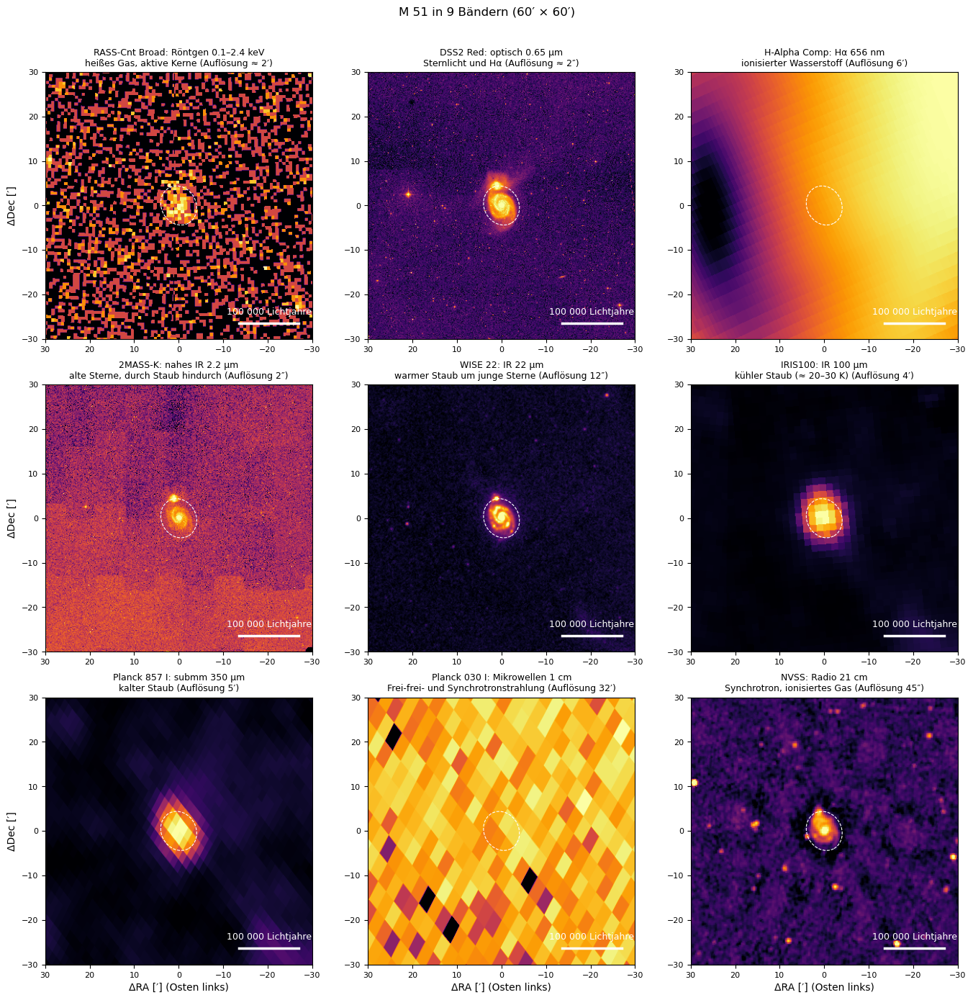

In [8]:
overview.wide_bands()

**8. Himmelshintergrund und radiales Profil**

Bei 3.4 µm folgt das Licht der Sternmasse, und Staub stört kaum. Gemittelt wird über Ellipsen mit der Form aus SIMBAD; der Himmel ist der Median außerhalb der Galaxie.

Das Profil fällt vom Zentrum über zwei Größenordnungen und erreicht bei 4.8′ das Rauschen des Himmels, nahe der großen Halbachse laut SIMBAD (4.5′). Zwischen 1′ und 2′ fällt es flacher: die Spiralarme. NGC 5195 liegt teilweise in den äußeren Ellipsen; der Median in den Ringen dämpft seinen Einfluss.

Himmel (Median außerhalb 1.1 a): 2.501, robuste Streuung 0.343  [WISE 3.4-Einheiten]
Profil: 40 Ringe bis 5.88'; Achsenverhältnis q = 0.86, PA = 28°
Zentrum 383.5, bei a: 3.70; Profil fällt unter 3 σ des Himmels bei 4.78'


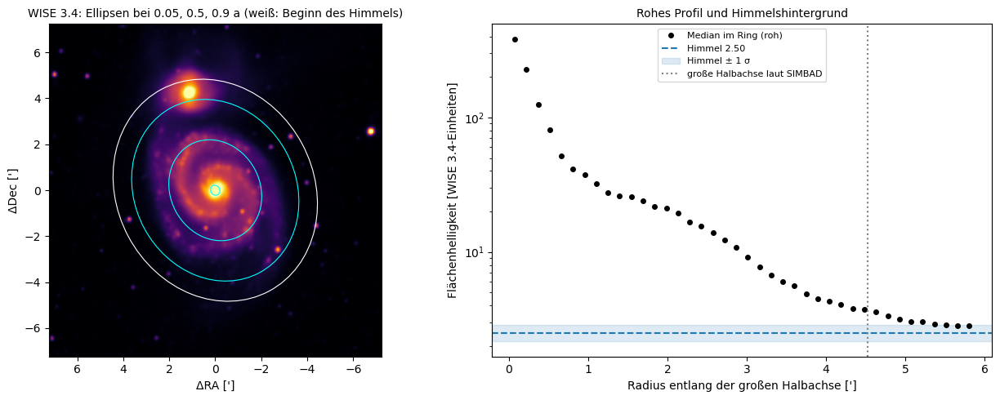

In [9]:
photometry.sky_profile()

**9. Das Sérsic-Profil**

Das Sérsic-Profil beschreibt Galaxien mit einem Index n: n = 1 ist eine exponentielle Scheibe, n = 4 ein elliptisches System. Angepasst wird zwischen 0.05 und 0.9 der großen Halbachse; innen stört die Auflösung von WISE (etwa 6″).

Es ergibt n = 0.88 ± 0.12 und einen Halblichtradius von 3.9 kpc: Die Galaxie ist scheibendominiert, mit einer Skalenlänge um 2.3 kpc, ähnlich der Milchstraße. Die Residuen sind aber nicht zufällig: Das Zentrum liegt über dem Modell (der Bulge), zwischen 2′ und 3′ ebenfalls (die Arme). Ein einzelnes Profil beschreibt zwei Bausteine nicht zugleich.

Sérsic-Fit in WISE 3.4 an 26 Ringe
  Sérsic-Index:     n = 0.88 ± 0.12   ->  scheibendominiert (Spirale, S0)
  Hubble-Typ:       SA  (SIMBAD)
  Effektivradius:   r_e = 1.70' ± 0.06' = 3.89 kpc
  Skalenlänge:      h ≈ r_e/1.678 = 1.02' = 2.32 kpc  (Milchstraße etwa 2.6 kpc)
  Neigung:          q = 0.86  ->  i = arccos q = 31° (dünne Scheibe)
  Residuen:         rms in ln I = 0.193


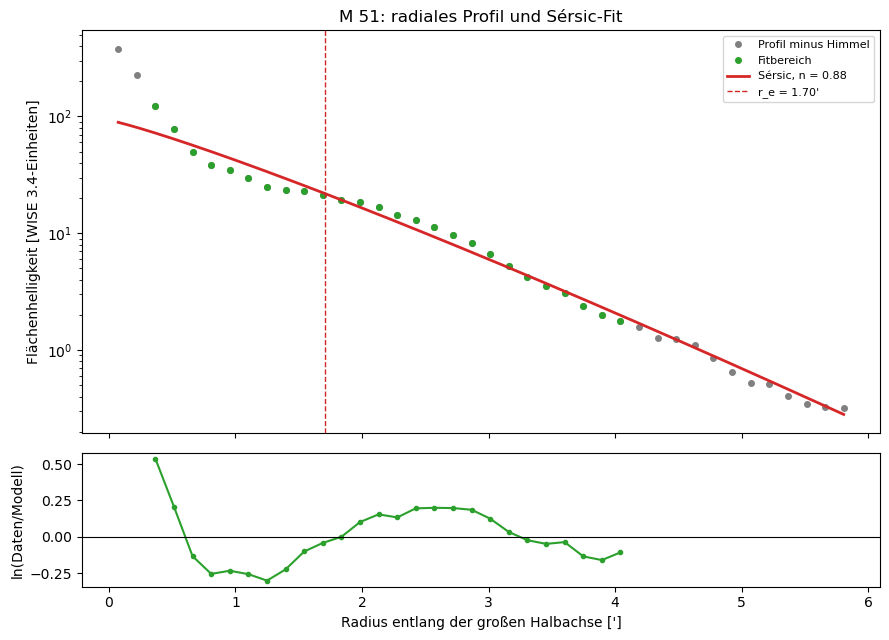

In [10]:
photometry.sersic_fit()

**10. Die Farbkarte**

NUV − W1 vergleicht das UV-Licht junger Sterne mit dem Licht der Sternmasse; beide Bilder werden dafür auf ähnliche Auflösung geglättet und vom Himmel befreit.

Blau, also junge Sterne, folgt den Spiralarmen; rot sind das Zentrum, die Bereiche zwischen den Armen und NGC 5195 im Norden. Am blauesten ist die Galaxie um 6 kpc, wo die Arme am kräftigsten sind. Die Scheibe ist im Mittel 0.74 mag blauer als das Zentrum: junge Sterne in den Armen, alte im Bulge.

Pixel mit beiden Bändern über 3 σ: 36527
NUV - W1 im Zentrum (r < 0.1 a): +0.61 mag, in der Scheibe (0.3-0.7 a): -0.13 mag
Die Scheibe ist um 0.74 mag blauer als das Zentrum


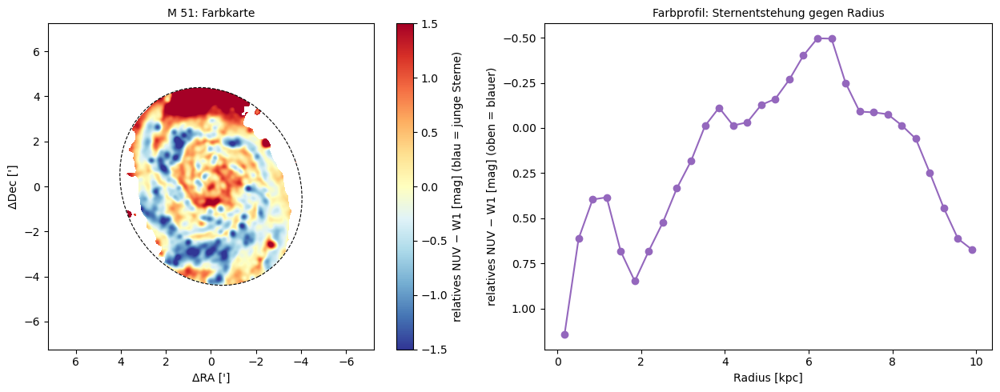

In [11]:
photometry.color_map()

**11. Bulge und Scheibe**

Angepasst wird die Summe aus einem Sérsic-Bulge und einer exponentiellen Scheibe; aus beiden Gesamtlichtern folgt der Anteil des Bulge am Licht, B/T.

Der Bulge dominiert nur innerhalb von etwa 0.5′, die Scheibe den ganzen Rest. B/T = 0.09 passt zu einer Sbc-Spirale, die Skalenlänge der Scheibe ist 2.43 kpc, und die Residuen sinken von 0.27 auf 0.16. Der Bulge ist mit 15″ nur zweieinhalb Auflösungselemente groß; seinen Index kann der Fit deshalb nicht messen.

Bulge und Scheibe in WISE 3.4 (Radien 0.2' bis 4.1')
  Bulge:   n = 0.50, r_e = 0.25' = 0.57 kpc   (n an der Grenze des Fits: Bulge kaum aufgelöst)
  Scheibe: h = 1.06' = 2.43 kpc
  B/T = 0.09   (Hubble-Typ SA)
  Residuen (rms in ln I): ein Sérsic-Profil 0.274  ->  Bulge und Scheibe 0.163


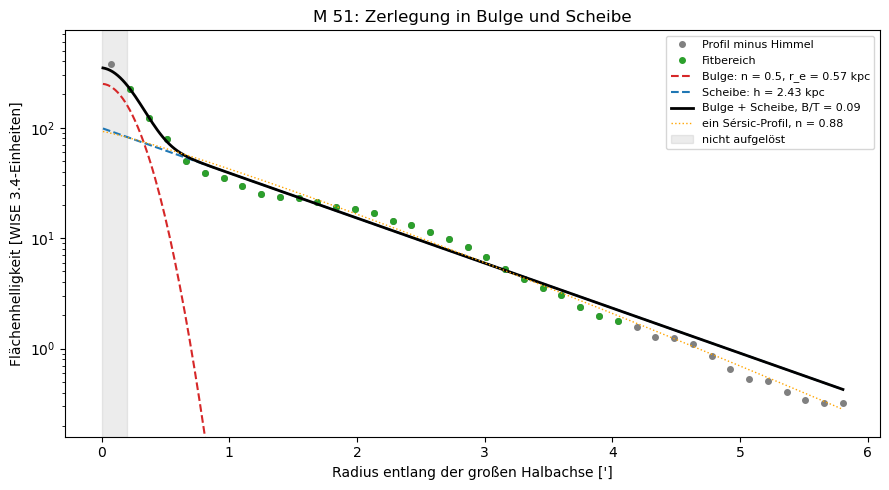

In [12]:
photometry.bulge_and_disk()

**12. Vergleich mit S4G**

Der Spitzer Survey S4G zerlegt Galaxien zweidimensional bei 3.6 µm mit viermal besserer Auflösung (Salo et al. 2015). Aus VizieR kommen der Eintrag für M 51 und seine Komponenten.

Für die Zerlegung stimmen die Größenordnungen: B/T 0.09 gegen 0.13, Skalenlänge 1.06′ gegen 1.40′. Ein einzelnes Sérsic-Profil stimmt dagegen gar nicht (n = 0.88 gegen 3.87): Eine Galaxie aus zwei Bausteinen hat kein einzelnes Sérsic-Profil, und der Index hängt davon ab, wie stark der Fit das helle Zentrum gewichtet.

In [13]:
photometry.s4g()

S4G: NGC5194, Modell '_bd' mit den Komponenten B (sersic), D (expdisk), Qualität 5

Entfernung für beide: 7.85 Mpc

                     Größe eigen (0.05-0.9 a) eigen (0-0.9 a)  S4G
      ein Sérsic-Profil: n               0.88            1.83 3.87
ein Sérsic-Profil: r_e [']               1.70            1.71 4.03
        Achsenverhältnis q      0.86 (SIMBAD)                 0.79
                       B/T               0.09                 0.13
                  Bulge: n               0.50                 1.00
            Bulge: r_e [']               0.25                 0.36
            Scheibe: h [']               1.06                 1.40
          Scheibe: h [kpc]               2.43                 3.20


**13. Spektren aus SDSS in M 51: drei Arten von Licht**

Der Sloan Digital Sky Survey hat mit Glasfasern von 3″ Durchmesser das Licht einzelner Stellen in Spektrographen geleitet, von 3800 bis 9200 Å. Gesucht werden alle Spektren um M 51, deren Geschwindigkeit innerhalb von 600 km/s der Geschwindigkeit laut SIMBAD liegt. Ein Spektrum zeigt, woraus das Licht besteht: Sternlicht gibt ein glattes Kontinuum mit Absorptionslinien von Calcium, Magnesium und Natrium, leuchtendes Gas schmale Emissionslinien des Wasserstoffs (Hα, Hβ) und die „verbotenen“ Linien von Sauerstoff, Stickstoff und Schwefel, die nur in sehr dünnem Gas entstehen.

SDSS hat um M 51 fünf passende Spektren, auf den Kern von M 51 selbst keines. Faser 1 liegt auf dem Kern des Begleiters NGC 5195, gut 4′ nördlich: ein Kontinuum, das zum Roten hin ansteigt, mit den Absorptionslinien von Natrium und Magnesium, also das Licht alter, kühler Sterne; an Emission ist nur [N II] zu sehen. Die Fasern 2 bis 4 liegen auf dem nördlichen Spiralarm: blaues Kontinuum junger Sterne und kräftige Emissionslinien des Gases in Sternentstehungsgebieten. Faser 5 ist ein Stern der Milchstraße im Vordergrund (Spektraltyp M3 III), dessen Geschwindigkeit nahe 0 noch ins Fenster fällt.

M 51: Geschwindigkeit 523 km/s laut SIMBAD; im Kasten von 9.0′ mit ±600 km/s 5 SDSS-Spektren (4 GALAXY, 1 STAR)
5 von 5 Spektren geladen (Cache M_51/sdss/)
1 Bilder, 14.5′ mit 600 Pixeln


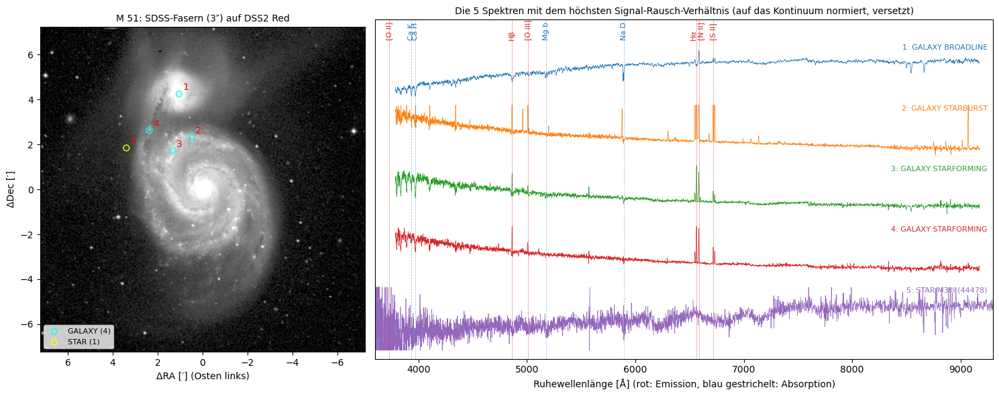

In [14]:
overview.m51_spectra()

**14. Emissionslinien in M 51 und das BPT-Diagramm**

In jedem Spektrum werden Hβ mit [O III], Hα mit [N II] und das [S II]-Paar mit Gaußprofilen auf einem geraden Kontinuum angepasst. Die Verhältnisse [N II]/Hα und [O III]/Hβ verraten, was das Gas ionisiert: Junge, heiße Sterne erzeugen wenig [N II], das härtere Licht eines aktiven Kerns oder Stoßwellen heben beide an. Daneben stehen die Werte derselben Fasern aus dem MPA-JHU-Katalog, der vor dem Messen ein Modell des Sternlichts abzieht; der eigene Fit tut das nicht.

Die drei Gebiete im Spiralarm liegen im Ast der Sternentstehung, Faser 3 knapp über der Kauffmann-Linie. [O III]/Hβ ist im eigenen Fit bei den Fasern 3 und 4 um 0.15 bis 0.17 dex höher als im Katalog, weil das gerade Kontinuum die Hβ-Absorption der Sterne nicht abzieht. Im Kern von NGC 5195 versagt der eigene Fit ganz: Links sieht man bei Hα statt einer Linie eine Mulde, die Absorption der alten Sterne, und nur [N II] ragt heraus. Erst nach Abzug des Sternlichts misst der Katalog log [N II]/Hα = +0.24 und log [O III]/Hβ = +0.28, weit über der Kewley-Linie: ein schwach aktiver Kern (LINER). Die H-II-Regionen von M 101 liegen dagegen in Schritt 18 alle im Ast der Sternentstehung.

BPT aus dem eigenen Fit: 3 Fasern (Sternentstehung 2, Übergang 1); nur aus MPA-JHU: 1
   2 STARBURST    v =  393 km/s, log [N II]/Hα = -0.41, log [O III]/Hβ = -0.79 → Sternentstehung; MPA-JHU (-0.40, -0.79)
   3 STARFORMING  v =  411 km/s, log [N II]/Hα = -0.31, log [O III]/Hβ = -0.36 → Übergang; MPA-JHU (-0.36, -0.51)
   4 STARFORMING  v =  446 km/s, log [N II]/Hα = -0.45, log [O III]/Hβ = -0.46 → Sternentstehung; MPA-JHU (-0.48, -0.63)
   1 BROADLINE    eigener Fit: eine der vier Linien unter S/N 3; MPA-JHU: log [N II]/Hα = +0.24, log [O III]/Hβ = +0.28 → AGN oder LINER


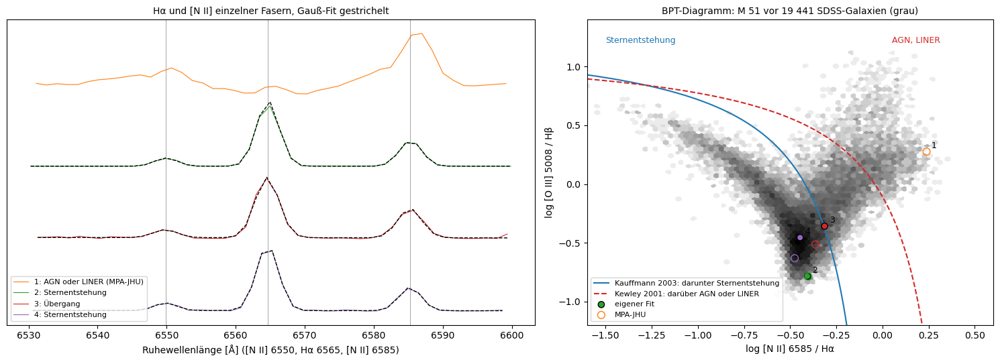

In [15]:
overview.m51_bpt()

**15. H-II-Regionen: M 101 und seine SDSS-Spektren**

Wo Sterne entstehen, leuchten H-II-Regionen, Gaswolken, die junge, heiße Sterne ionisieren. Aus wenigen hellen Linien liest man Dichte, Staub, was das Gas ionisiert und wie viel Sauerstoff es enthält; der Sauerstoff ist das Gedächtnis früherer Sterngenerationen. Der Sloan Digital Sky Survey (SDSS) hat zufällig Dutzende Fasern auf die Spiralgalaxie M 101 gesetzt, weil seine Zielauswahl die hellen Knoten in den Armen für eigene Galaxien hielt.

M 101 steht 6.83 Mpc entfernt (1′ = 1.99 kpc) und ist fast von oben zu sehen. 57 Spektren haben die passende Geschwindigkeit; die cyanen Fasern sitzen fast alle auf hellen Knoten in den Armen, die gelben (Klasse STAR) liegen verstreut. Das Spektrum im Zentrum zeigt Sternlicht mit Absorptionslinien und darauf Hβ, Hα, [N II] und [S II].

M 101: Hubble-Typ S_AB, v_sys = 243 km/s, D = 6.83 Mpc (1' = 1.99 kpc), Durchmesser 21.9', q = 0.95
57 SDSS-Spektren geladen; Klassen der Pipeline: {'GALAXY': 50, 'STAR': 7}
Mit Linienflüssen im MPA-JHU-Katalog: 57


hips2fits (CDS) nicht erreichbar: Farbbild aus SkyView DSS2 Rot und Blau


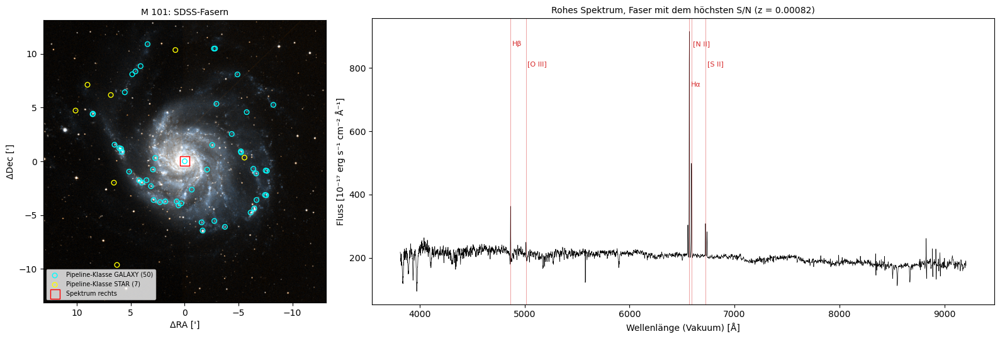

In [16]:
hiiregions.sdss_spectra()

**16. Linienfits**

Für jede Faser werden vier Liniengruppen mit Gaußprofilen auf einem linearen Kontinuum angepasst: Hβ, [O III], [N II] mit Hα, und [S II].

Die Fits liegen fast genau auf den Daten. 55 von 57 Spektren lassen sich anpassen; 9 Linien fallen weg, weil der Detektor in den hellsten Regionen gesättigt war. Die eigene Geschwindigkeit stimmt mit SDSS auf 2 ± 6 km/s überein. Die Regionen streuen um ±70 km/s um die Geschwindigkeit der Galaxie: die Rotation der Scheibe. Die STAR-Spektren sind Vordergrundsterne.

55 von 57 Spektren angepasst; 9 Linien verworfen, weil ihr Kern maskierte Pixel enthält
  Hb: in 1 Spektren
  OIII4959: in 1 Spektren
  OIII5007: in 3 Spektren
  Ha: in 4 Spektren
  Ha        mit S/N > 3:  45
  Hb        mit S/N > 3:  46
  OIII5007  mit S/N > 3:  44
  NII6584   mit S/N > 3:  47
  SII6717   mit S/N > 3:  48
  SII6731   mit S/N > 3:  46
Eigene Geschwindigkeit aus Hα minus SDSS-Rotverschiebung: Median +1.8 km/s, Streuung 5.6 km/s
Geschwindigkeiten der 43 Regionen mit Hα und [N II]: 174 bis 310 km/s (v_sys laut SIMBAD 243 km/s)
Spektren der Klasse STAR: 7, davon mit [N II]: 0; Geschwindigkeiten -399, -200, -124, -88, -6, 83, 234 km/s


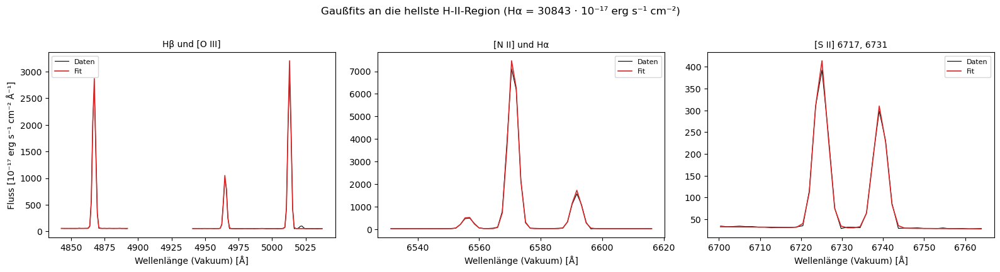

In [17]:
hiiregions.line_fits()

**17. Dichte und Staub**

Das Verhältnis der beiden [S II]-Linien hängt von der Elektronendichte ab, das Verhältnis Hα/Hβ ohne Staub nur von der Atomphysik (2.86); der Überschuss ist die Rötung.

Das [S II]-Verhältnis liegt bei 1.40, fast am Grenzwert für sehr dünnes Gas: etwa 34 Elektronen pro cm³. Alle Regionen haben Hα/Hβ über 2.86, im Median 3.76: Staub schluckt etwa die Hälfte des Hα-Lichts.

[S II] 6717/6731 in 42 Regionen: Median 1.398 (16.-84. Perzentil 1.31 bis 1.45)
  -> n_e ≈ 34 cm⁻³ aus dem Median; 17% der Regionen liegen über dem Grenzwert 1.45 für n_e -> 0
Hα/Hβ in 42 Regionen: Median 3.76 (ohne Staub 2.86)
  -> E(B-V) ≈ 0.28 mag, A_V ≈ 0.85 mag, also 47% des Hα-Lichts und 60% des Hβ-Lichts vom Staub geschluckt
  Regionen mit Hα/Hβ < 2.86 (unphysikalisch, Rauschen oder Absorption der Sterne unter Hβ): 0


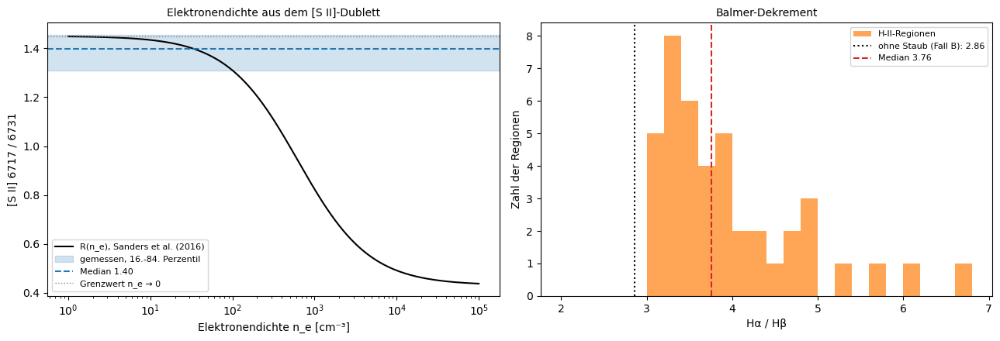

In [18]:
hiiregions.density_dust()

**18. Das BPT-Diagramm**

Das BPT-Diagramm aus vier Linien trennt Gas, das junge Sterne ionisieren, von Gas um einen aktiven Kern. Die H-II-Regionen erscheinen vor 20 000 SDSS-Galaxien.

Die SDSS-Galaxien bilden die typische Möwenform: links die Sequenz der Sternentstehung, rechts oben der Arm der AGN. Alle 41 Regionen von M 101 liegen auf dem linken Arm, geordnet nach dem Radius: innen metallreich mit viel [N II], außen metallarm mit heißerem Gas. Die Sequenz der Sternentstehung ist vor allem eine Sequenz der Metallizität; M 101 hat keinen aktiven Kern.

M 101: 41 Regionen mit allen vier Linien über S/N 3: {'Sternentstehung': 40, 'Mischform': 1}
Vergleichsgalaxien (20,000): {'Sternentstehung': '71%', 'Mischform': '18%', 'AGN': '11%'}
Bereich der H-II-Regionen: log [N II]/Hα von -1.47 bis -0.37, log [O III]/Hβ von -0.83 bis 0.81


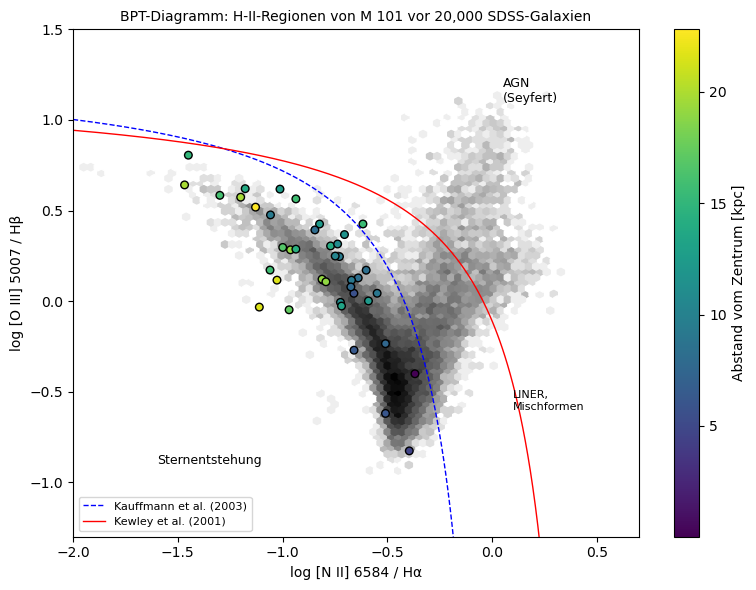

In [19]:
hiiregions.bpt()

**19. Der Metallizitätsgradient**

Aus den Linienverhältnissen N2 und O3N2 folgt mit den Eichungen von Pettini und Pagel die Sauerstoffhäufigkeit; dagegen der Abstand vom Zentrum.

Die Häufigkeit fällt von etwa der Sonnenhäufigkeit im Zentrum auf ein Drittel davon in den äußeren Armen, um 0.02 dex pro kpc, in beiden Eichungen fast gleich. Scheibengalaxien sind von innen nach außen gewachsen: Innen haben mehr Sterngenerationen das Gas angereichert.

38 Regionen mit Sternentstehung, Abstände 0.0 bis 22.8 kpc (Katalogradius 21.7 kpc)
  O3N2 : 12 + log(O/H) = 8.67 ± 0.05 -0.0204 ± 0.0039 × R[kpc], Streuung um die Gerade 0.126 dex, über den Katalogradius -0.44 dex
  N2   : 12 + log(O/H) = 8.67 ± 0.03 -0.0189 ± 0.0026 × R[kpc], Streuung um die Gerade 0.083 dex, über den Katalogradius -0.41 dex


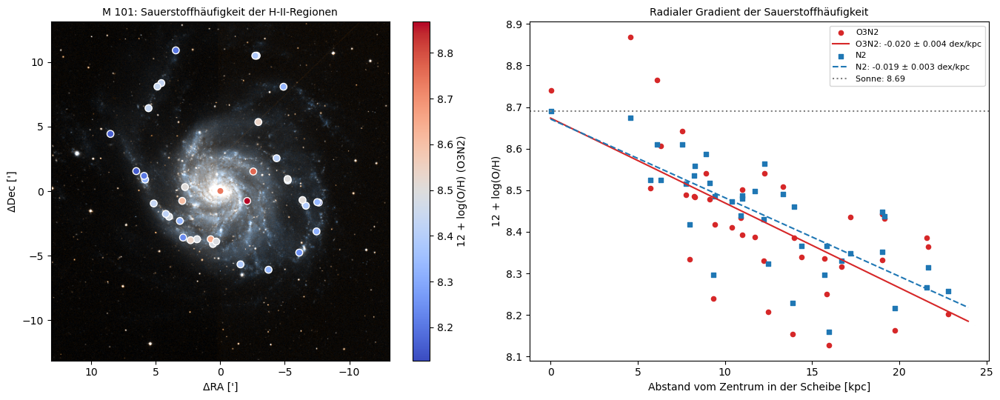

In [20]:
hiiregions.metallicity_gradient()

**20. Vergleich mit der SDSS-Pipeline und dem MPA-JHU-Katalog**

Die eigenen Linienflüsse gegen die der SDSS-Pipeline und des MPA-JHU-Katalogs, Faser für Faser, und die Gradienten in drei Eichungen.

Mit der Pipeline stimmen die Hα-Flüsse auf 1 % überein. MPA-JHU liegt für alle Linien um denselben Faktor 1.37 tiefer, ein Unterschied in der Flusseichung, der für Linienverhältnisse keine Rolle spielt. Die Eichung von MPA-JHU liegt im Zentrum 0.6 dex höher und fällt doppelt so steil: Dieselben Spektren geben je nach Eichung andere Nullpunkte, aber alle zeigen den Abfall nach außen.

Hα eigen / SDSS-Pipeline (45 Fasern): Median 0.991, Streuung 0.062
Ha        eigen / MPA-JHU (40 Fasern): Median 1.373, Streuung 0.503
Hb        eigen / MPA-JHU (41 Fasern): Median 1.329, Streuung 0.530
OIII5007  eigen / MPA-JHU (41 Fasern): Median 1.413, Streuung 0.498
NII6584   eigen / MPA-JHU (43 Fasern): Median 1.429, Streuung 0.533
Linienverhältnisse (38 Fasern): log [N II]/Hα eigen minus MPA-JHU +0.012, log [O III]/Hβ +0.025
Faktor eigen/MPA-JHU für Hα pro Faser: 1.24 bis 1.57 (10.-90. Perzentil); die Faktoren der anderen Linien derselben Faser weichen im Median ab um {'Hb': '4.4%', 'OIII5007': '2.0%', 'NII6584': '3.4%'}
Balmer-Dekrement pro Faser eigen / MPA-JHU: Median 1.046; E(B-V) eigen minus MPA-JHU: Median +0.045 mag

Gradient aus MPA-JHU (oh_p50, Tremonti et al. 2004; 34 Regionen): 12 + log(O/H) = 9.28 -0.0407 ± 0.0049 × R[kpc]
Nullpunkte im Zentrum: O3N2 8.67, N2 8.67, MPA-JHU 9.28; Sonne 8.69


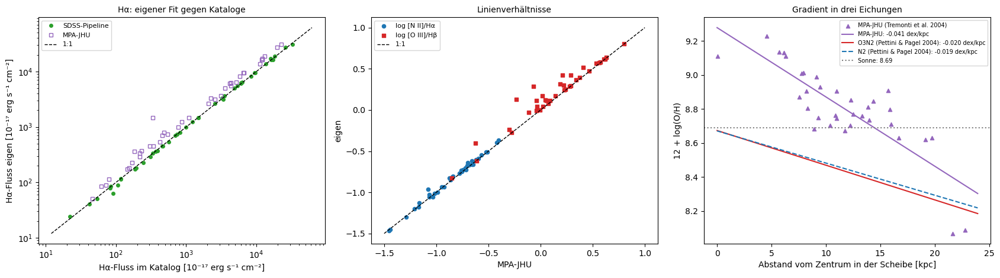

In [21]:
hiiregions.pipeline_check()

**21. Rotationskurven: die SPARC-Datenbank**

Sterne und Gas einer Scheibengalaxie laufen auf fast kreisförmigen Bahnen; die Geschwindigkeit hängt nur von der Masse innerhalb der Bahn ab. Wer die Rotation in verschiedenen Abständen misst, wiegt die Galaxie. Seit Rubin und Bosma (um 1980) weiß man, dass die Kurven außen flach bleiben, statt abzufallen wie die Planeten um die Sonne: Dort muss Masse sein, die man nicht sieht. Geladen wird die SPARC-Datenbank mit 175 Scheibengalaxien, Spitzer-Photometrie und Rotationskurven aus HI und Hα.

Die 175 Galaxien haben 3391 Messpunkte, flache Geschwindigkeiten von 19 bis 332 km/s. Fast alle Kurven steigen innen an und bleiben dann flach; kaum eine fällt außen ab. Das Beispiel NGC 2403 steigt bis 5 kpc auf 120 km/s und bleibt bei 130 km/s, gemessen bis 21 kpc, 15 Skalenlängen weit: Das HI reicht weit über die Sterne hinaus.

SPARC: 175 Galaxien, 3,391 Punkte auf den Rotationskurven
Hubble-Typen: {'Im': 39, 'Sm': 27, 'Sbc': 18, 'Sd': 16, 'Sc': 16, 'Scd': 16, 'Sb': 12, 'Sab': 10, 'Sdm': 10, 'BCD': 5, 'S0': 3, 'Sa': 3}
V_flat von 19 bis 332 km/s, Entfernungen von 1.0 bis 128 Mpc

NGC 2403 = NGC2403: Typ Scd, D = 3.16 ± 0.16 Mpc, Neigung 63° ± 3°, L[3.6] = 10.0·10⁹ L_sun, M_HI = 3.20·10⁹ M_sun, Skalenlänge 1.39 kpc, V_flat = 131 ± 5 km/s, Qualität 1
73 Punkte von 0.16 bis 20.9 kpc (= 15.0 Skalenlängen)


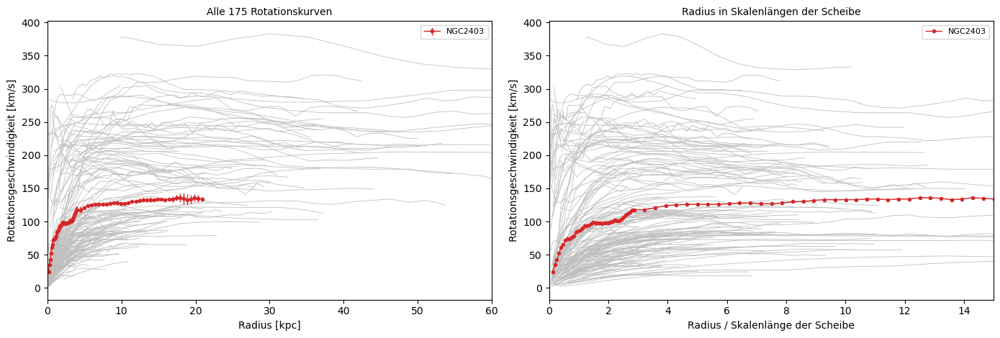

In [22]:
rotation.sparc_data()

**22. Qualitätsschnitte**

Behalten werden Galaxien guter oder mittlerer Qualität mit einer Neigung ab 30° (darunter wird die Korrektur 1/sin i groß und unsicher) und Punkte mit weniger als 10 % Fehler, wie in den Arbeiten des SPARC-Teams.

Von 3391 Punkten bleiben 2696 aus 147 Galaxien. Der Schnitt auf den Fehler entfernt am meisten, fast 500 Punkte aus einem langen Ausläufer bis 50 %.

alle                          3391 Punkte aus 175 Galaxien
Qualität 1 oder 2             3271 Punkte aus 163 Galaxien
Neigung >= 30°                3168 Punkte aus 153 Galaxien
Fehler < 10 % von V_obs       2696 Punkte aus 147 Galaxien
V_obs > 0 und V_bar² > 0      2696 Punkte aus 147 Galaxien


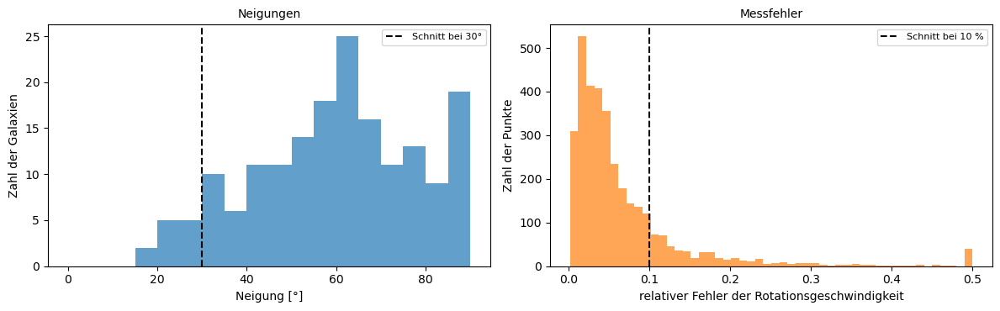

In [23]:
rotation.quality_cuts()

**23. Sichtbare Materie gegen beobachtete Rotation**

Für NGC 2403 werden die Beiträge von Gas, Sternscheibe und Bulge im Quadrat addiert und mit der beobachteten Kurve verglichen; daraus folgt der Anteil der Dunklen Materie innerhalb jedes Radius.

Die Sterne dominieren innen, das Gas ab 11 kpc; zusammen erreichen sie höchstens 76 km/s und fallen dann ab, die Messung steigt aber auf 134 km/s. Der Anteil der Dunklen Materie liegt innen bei 40 bis 55 % und steigt außen auf 85 %. Innerhalb von 21 kpc wiegt die Galaxie 8.7·10¹⁰ Sonnenmassen, sichtbar sind nur 1.3·10¹⁰.

Bei 2.2 Skalenlängen (3.1 kpc): V_bar = 74 km/s, V_obs = 102 km/s, Anteil Dunkle Materie 47%
Am letzten Punkt (20.9 kpc): V_bar = 51 km/s, V_obs = 134 km/s, Anteil Dunkle Materie 85%
Ab 3.5 kpc (= 2.5 Skalenlängen) bleibt der Anteil der Dunklen Materie über 50 %
Masse innerhalb 21 kpc (kugelsymmetrisch genähert): gesamt 8.71e+10 M_sun, sichtbar 1.28e+10 M_sun


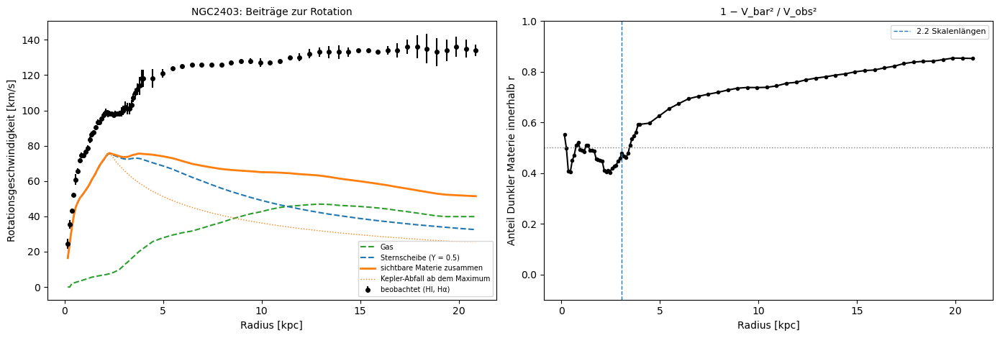

In [24]:
rotation.baryons_vs_rotation()

**24. NFW-Halo gegen Halo mit Kern**

Zur sichtbaren Materie kommt ein Halo aus Dunkler Materie: das NFW-Profil aus kosmologischen Simulationen, dessen Dichte zum Zentrum steil ansteigt, oder ein pseudo-isothermes Profil mit flachem Kern, wie es viele Zwerggalaxien zeigen.

Für NGC 2403 passt NFW besser (χ²_red 4.9 gegen 12.8): Der Halo mit Kern steigt innen zu langsam an. Beide verfehlen eine Stufe bei 2 bis 3 kpc. Der Halo hat 38-mal die sichtbare Masse; nach dem kosmischen Verhältnis von Baryonen zu Materie wären es 6, die Galaxie enthält also nur ein Sechstel der Baryonen, die zu ihrem Halo gehören.

NFW:       V200 = 104 ± 1 km/s, c = 10.1 ± 0.2, R200 = 142 kpc, M200 = 3.6e+11 M_sun, r_s = 14.1 kpc;  χ²_red = 4.89
Mit Kern:  V_inf = 127 ± 1 km/s, r_c = 1.65 ± 0.03 kpc;  χ²_red = 12.75
Besser passt NFW (χ²_red 4.89 gegen 12.75)
Sichtbare Masse gegen Halo: M_bar(gesamt) = 9.3e+09 M_sun, M200 / M_bar = 38


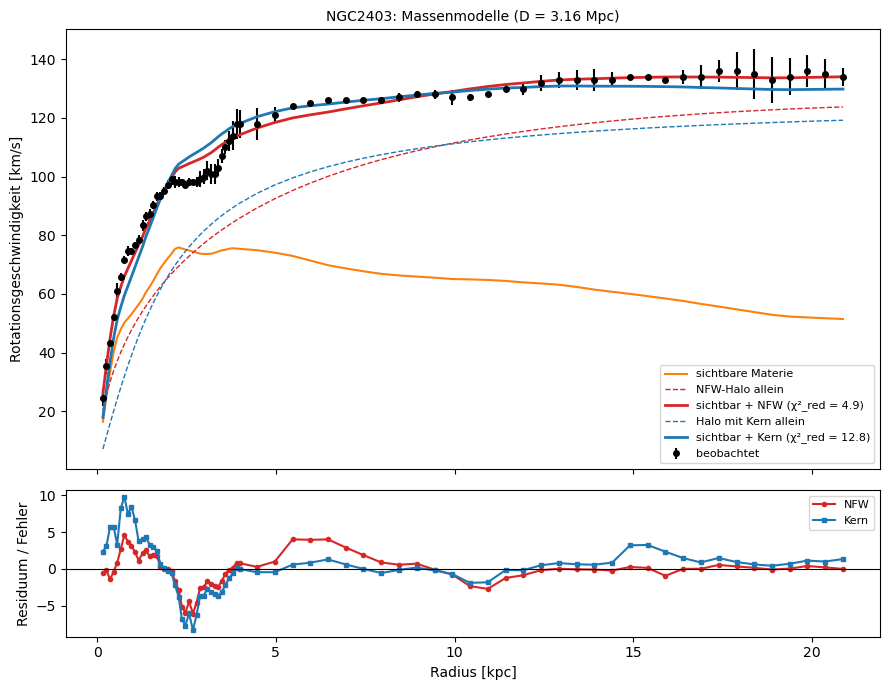

In [25]:
rotation.halo_fits()

**25. Die radiale Beschleunigungsrelation**

Für jeden Punkt aller Galaxien: die gemessene Beschleunigung v²/r gegen die, die Sterne und Gas allein erzeugen würden. Ohne Dunkle Materie lägen alle Punkte auf der Diagonale.

Bei hohen Beschleunigungen liegen die Punkte nahe der Diagonale, unter etwa 10⁻¹⁰ m/s² biegen sie nach oben ab. Eine Kurve mit einer einzigen Konstanten, g† = 1.16·10⁻¹⁰ m/s², beschreibt alle 147 Galaxien mit nur 0.13 dex Streuung. Aus der sichtbaren Materie folgt die Rotation also fast vollständig, obwohl die Dunkle Materie den größten Teil der Masse stellt; manche deuten das als Hinweis auf eine geänderte Schwerkraft (MOND).

2,696 Punkte aus 147 Galaxien
g† = (1.161 ± 0.018)·10⁻¹⁰ m/s² (nur statistischer Fehler)
Streuung um die Kurve: 0.133 dex; ohne Dunkle Materie (g_obs = g_bar): 0.281 dex um einen Mittelwert von +0.43 dex
  log g_bar in [-12.5, -11.5):  155 Punkte, g_obs/g_bar im Median   7.8
  log g_bar in [-11.5, -10.5): 1296 Punkte, g_obs/g_bar im Median   3.9
  log g_bar in [-10.5, -9.5):  933 Punkte, g_obs/g_bar im Median   1.8
  log g_bar in [-9.5, -8.5):  302 Punkte, g_obs/g_bar im Median   1.1


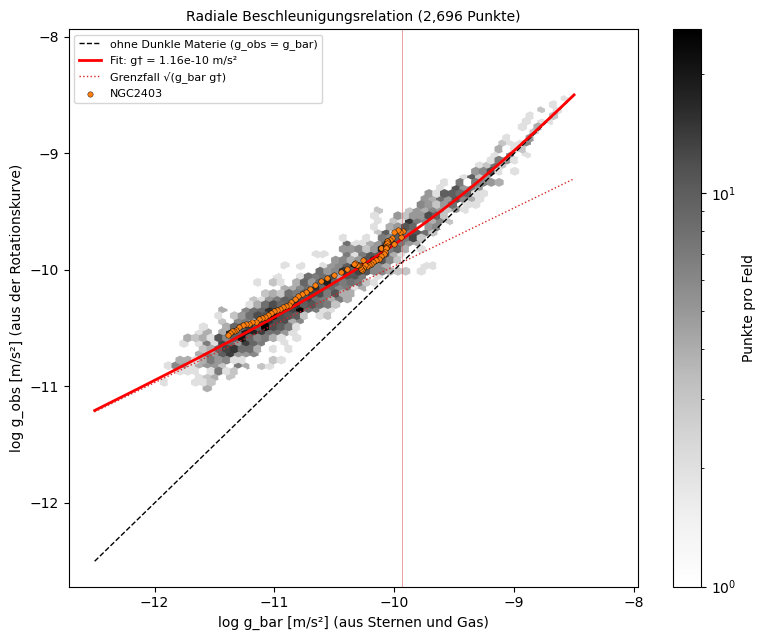

In [26]:
rotation.radial_acceleration()

**26. Die baryonische Tully-Fisher-Beziehung**

Die gesamte sichtbare Masse (Sterne und Gas) gegen die flache Rotationsgeschwindigkeit; aus g† folgt die Vorhersage M = V⁴/(G g†).

129 Galaxien liegen auf einem engen Band über mehr als drei Größenordnungen in der Masse, mit der Steigung 3.56 ± 0.09; die gewöhnliche Regression gibt 3.41, zu flach, weil auch V Fehler hat. Bei 100 km/s trifft die Vorhersage die Masse auf 0.09 dex. Bei Zwergen ist der größte Teil der sichtbaren Masse Gas (78 %), bei großen Spiralen nur 13 %; ohne das Gas wäre die Beziehung nicht so eng.

129 Galaxien mit V_flat und Qualität 1 oder 2
Orthogonale Regression: log M_bar = (3.56 ± 0.09) log V_flat + (2.60 ± 0.19), Streuung 0.25 dex
Gewöhnliche Regression: Steigung 3.41 (zu flach)
Aus g†: Steigung 4, log M_bar = 4 log V_flat + 1.81;  bei V_flat = 100 km/s: Fit 5.33e+09, Vorhersage 6.49e+09 M_sun
Gasanteil: von 2% bis 95%; Median unter 50 km/s 78%, über 200 km/s 13%


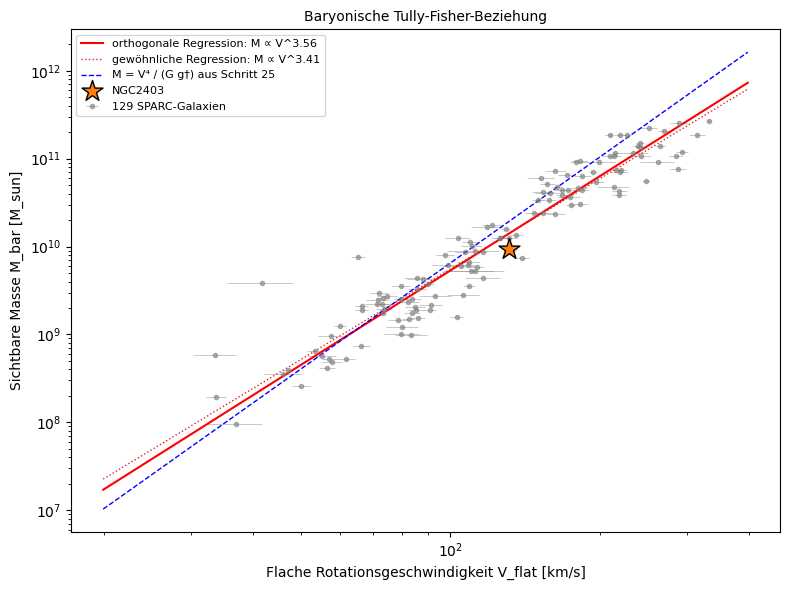

In [27]:
rotation.tully_fisher()

**27. Vergleich mit den SPARC-Veröffentlichungen**

Die eigenen Werte neben denen von McGaugh, Lelli und Schombert.

g† liegt 3 % unter dem veröffentlichten Wert 1.20·10⁻¹⁰ m/s², weit innerhalb von dessen systematischem Fehler; Streuung und Zahl der Punkte (2696 gegen 2693) stimmen. Die Steigung 3.56 liegt im veröffentlichten Bereich von 3.5 bis 4, der von der Definition der Geschwindigkeit abhängt.

In [28]:
rotation.literature()

                                     Größe                             eigen                     veröffentlicht                            Quelle
                           g† [10⁻¹⁰ m/s²]                       1.16 ± 0.02 1.20 ± 0.02 (stat.) ± 0.24 (syst.) McGaugh, Lelli & Schombert (2016)
Streuung der Beschleunigungsrelation [dex]                              0.13                               0.13 McGaugh, Lelli & Schombert (2016)
                           Zahl der Punkte                             2,696                              2,693 McGaugh, Lelli & Schombert (2016)
       Steigung der Tully-Fisher-Beziehung                       3.56 ± 0.09    etwa 3.5 bis 4, je nach Methode         Lelli et al. (2016, 2019)
                 V_flat von NGC2403 [km/s] 135 (Mittel der letzten 3 Punkte)                            131 ± 5                     SPARC-Tabelle


**28. Warps: Galaxien in Kantenlage**

Die Scheibe einer Spiralgalaxie ist innen meist eben, außen aber oft verbogen wie eine Hutkrempe, auch die Milchstraße. Eine ungestörte Scheibe sollte eben bleiben; ein Warp verrät deshalb, was um die Galaxie geschieht: ein gekippter Halo aus Dunkler Materie, einfallendes Gas mit anderem Drehimpuls oder Gezeitenkräfte von Begleitern. Hier wird die Verbiegung in Bildern der DESI Legacy Surveys gemessen und mit dem Katalog von Sánchez-Saavedra et al. (2003) verglichen; Beispiel ist ESO 240-011.

ESO 240-011 in mehreren Bändern ist eine dünne, gerade Nadel. Im UV leuchtet die Scheibe gleichmäßig schmal, weil junge Sterne nahe der Mittelebene sitzen, optisch ist sie innen dicker und gelblich. Mit bloßem Auge ist in keinem Band eine Verbiegung zu sehen; dafür braucht es die Messung.

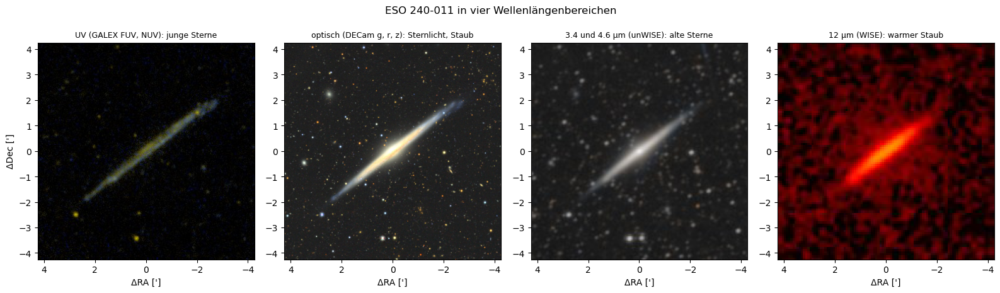

In [29]:
warps.load()

**29. Bild und Katalogdaten**

SIMBAD liefert Position, Größe, Positionswinkel und die Entfernungen ohne Rotverschiebung, der Legacy-Survey-Viewer den Ausschnitt im r-Band.

Die Galaxie ist 5.3′ lang und 44.3 Mpc entfernt (meist Tully-Fisher), ein Pixel entspricht 137 pc. Im r-Band ist sie eine schmale Scheibe mit hellem Zentrum; rundherum liegen Vordergrundsterne und kleine Hintergrundgalaxien, die bei der Messung herausfallen müssen.

ESO 240-011: RA 354.4559, Dec -47.7273, z = 0.00951, große Achse 5.3'
D = 44.3 Mpc (Median aus 6 Messungen ohne Rotverschiebung; cz/H0 = 40.7 Mpc)
1 px = 0.638" = 137 pc, Bild 800 x 800 px


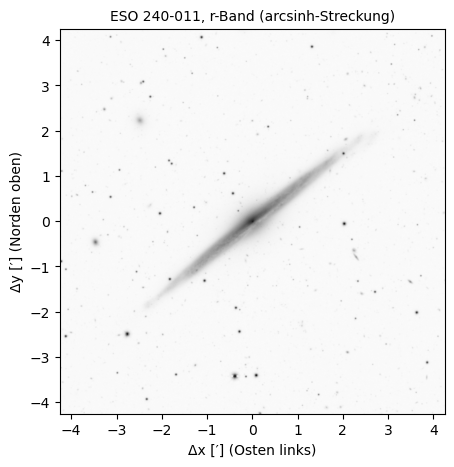

In [30]:
warps.image()

**30. Himmel abziehen und Bild drehen**

Nach Abzug des Himmels ist die Galaxie die zusammenhängende Fläche über 3 σ; Schwerpunkt und zweite Momente ihrer Helligkeit geben die Achse, und das Bild wird gedreht, bis die Scheibe waagerecht liegt.

Der eigene Positionswinkel ist 128.1°, der Katalog sagt 128°. Die Galaxie reicht 42.6 kpc weit und ist damit gut 85 kpc lang, fast dreimal so groß wie die Sternscheibe der Milchstraße.

In [31]:
warps.orientation()

Himmelsrauschen: 0.000862 (Bildeinheiten)
PA = 128.1 Grad (Katalog: 128 Grad)
R_max (3-sigma-Isophote, geglättet) = 311 px = 42.6 kpc


**31. Spine-Fit**

In jeder Gruppe von drei Bildspalten gibt ein Gauß-Fit die Höhe der hellsten Stelle, die Spine. Spalten mit wenig Signal, Sternen oder Ausreißern fallen weg.

Von 207 Spalten bleiben 170. Die Spine ist keine Gerade: in der Mitte eine flache Kuppel, nach Osten fällt sie gleichmäßig um 5 Pixel ab, nach Westen um 3, und ganz außen knickt sie auf der Westseite steil ab, bei kleinem Signal.

207 Spalten gefittet, 170 behalten (SNR > 5.0, Ausreißer entfernt)


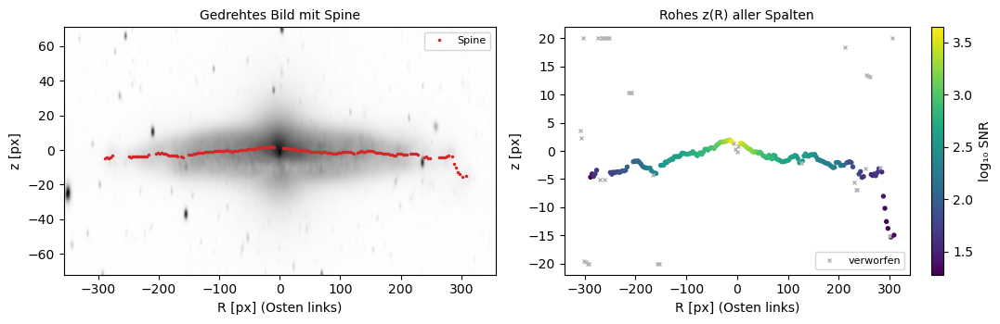

In [32]:
warps.spine_fit()

**32. Referenzebene und Form des Warps**

Durch die innere Spine wird eine Gerade gelegt; der Abstand aller Punkte von ihr ist das Warp-Profil. Für jede Seite folgen Amplitude und Winkel im äußersten Viertel und daraus die Form: S (die Seiten biegen gegensinnig), U (gleichsinnig) oder einseitig.

Die Ostseite liegt außen 842 pc unter der Ebene (Winkel −1.5°), die Westseite nur 255 pc: ein einseitiger Warp. Die Einordnung ist aber empfindlich; mit einem größeren inneren Bereich würde ein U daraus. Fest steht, dass die Ostseite um etwa 0.8 kpc nach unten verbogen ist.

Innere Gerade: a = -0.0097 (Restdrehung -0.55 Grad), b = +0.06 px
Streuung innen s = 153 pc
Ostseite: z_warp = -842 pc (5.5 s) bei R = 32.9 kpc, Warp-Winkel -1.5 Grad
Westseite: z_warp = -255 pc (1.7 s) bei R = 37.7 kpc, Warp-Winkel -0.4 Grad
S-Anteil 294 pc, U-Anteil 549 pc  ->  L-Warp (einseitig), klar


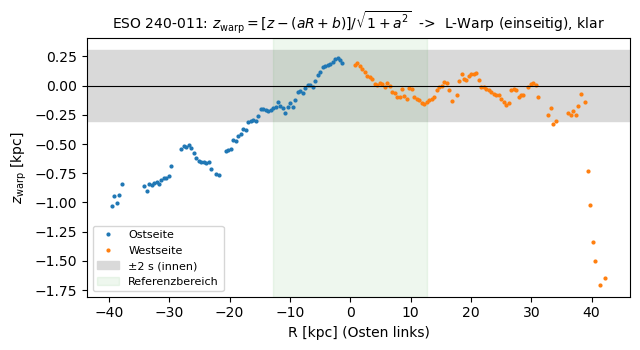

In [33]:
warps.warp_shape()

**33. Staub oder Geometrie?**

Staub schwächt blaues Licht stärker als rotes. Eine echte Verbiegung erscheint in allen Bändern gleich, ein Staubeffekt nicht; dieselbe Messung läuft deshalb auch im g- und z-Band.

Die Profile in g, r und z liegen fast überall aufeinander, auch auf der verbogenen Ostseite: Die Verbiegung ist geometrisch. Nur die äußerste Westspitze unterscheidet sich, und allein sie macht im g-Band einen U-Warp aus der Form.

g: Ost  -799 pc, West  -987 pc, s = 225 pc  ->  U-Warp, klar
r: Ost  -842 pc, West  -255 pc, s = 153 pc  ->  L-Warp (einseitig), klar


z: Ost  -842 pc, West    -3 pc, s = 113 pc  ->  L-Warp (einseitig), klar


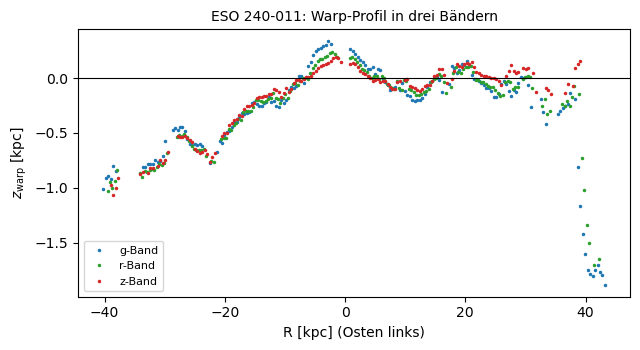

In [34]:
warps.dust_or_geometry()

**34. Stichprobe und Warp-Katalog**

Sieben Galaxien: zwei, die der Katalog als eben führt, drei mit S-Warp und zwei nördliche mit bekannten Warps im Wasserstoff (NGC 5907, NGC 4013). Die Tabelle stellt die eigene Messung neben den Katalog.

Alle Positionswinkel stimmen mit SIMBAD auf 0.1° bis 1.9°. Die Katalog-S-Warps findet die Methode wieder, mit kleineren Winkeln, weil der Katalog den äußersten Punkt von Auge beurteilt und hier der Median des äußeren Viertels zählt. Bei NGC 4013 verschwindet der Warp im z-Band fast: größtenteils Staub. Der berühmte Wasserstoff-Warp von NGC 5907 liegt weiter draußen, als die Sterne reichen.

In [35]:
warps.sample()

,D [Mpc],PA eigen,PA Katalog,R_max [kpc],Ost [pc],West [pc],s [pc],ψ Ost/West [°],Klasse (r),Klasse (z),SS03
Galaxie,,,,,,,,,,,
ESO 240-011,44.3,128.1,128.0,42.6,-842,-255,153,1.5 / 0.4,"L-Warp (einseitig), klar","L-Warp (einseitig), klar","kein, 0° / 0°"
IC 2531,35.6,74.3,74.0,42.2,-61,-82,62,0.1 / 0.2,kein Warp,kein z-Bild,"kein, 0° / 0°"
IC 5176,25.6,28.4,28.0,20.2,-548,534,80,1.9 / 1.8,"S-Warp, klar","S-Warp, klar","S, 3° / 3°"
IC 4351,31.1,19.9,18.0,31.8,681,-397,111,1.5 / 0.9,"S-Warp, klar","S-Warp, klar","S, 6° / 7°"
IC 2000,18.4,81.0,82.0,15.1,-76,377,108,0.4 / 1.8,"L-Warp (einseitig), schwach","L-Warp (einseitig), klar","S, 5° / 5°"
NGC 4013,17.9,64.9,64.0,15.3,-147,137,32,0.7 / 0.6,"S-Warp, klar","L-Warp (einseitig), schwach",–
NGC 5907,15.8,155.5,155.0,30.5,-43,-427,94,0.1 / 1.0,"L-Warp (einseitig), klar","U-Warp, klar",–


**35. Die Warp-Profile im Vergleich**

Die sieben Warp-Profile im r-Band nebeneinander, jeweils mit dem Streifen der doppelten inneren Streuung.

IC 5176 und IC 4351 zeigen einen S-Warp mit verschiedenem Drehsinn, IC 2531 eine ebene Scheibe, ESO 240-011, IC 2000 und NGC 5907 einen einseitigen Warp. Die Amplituden sind klein, einige hundert Parsec bei Scheiben von 15 bis 40 kpc Radius, also Winkel von 1° bis 2°.

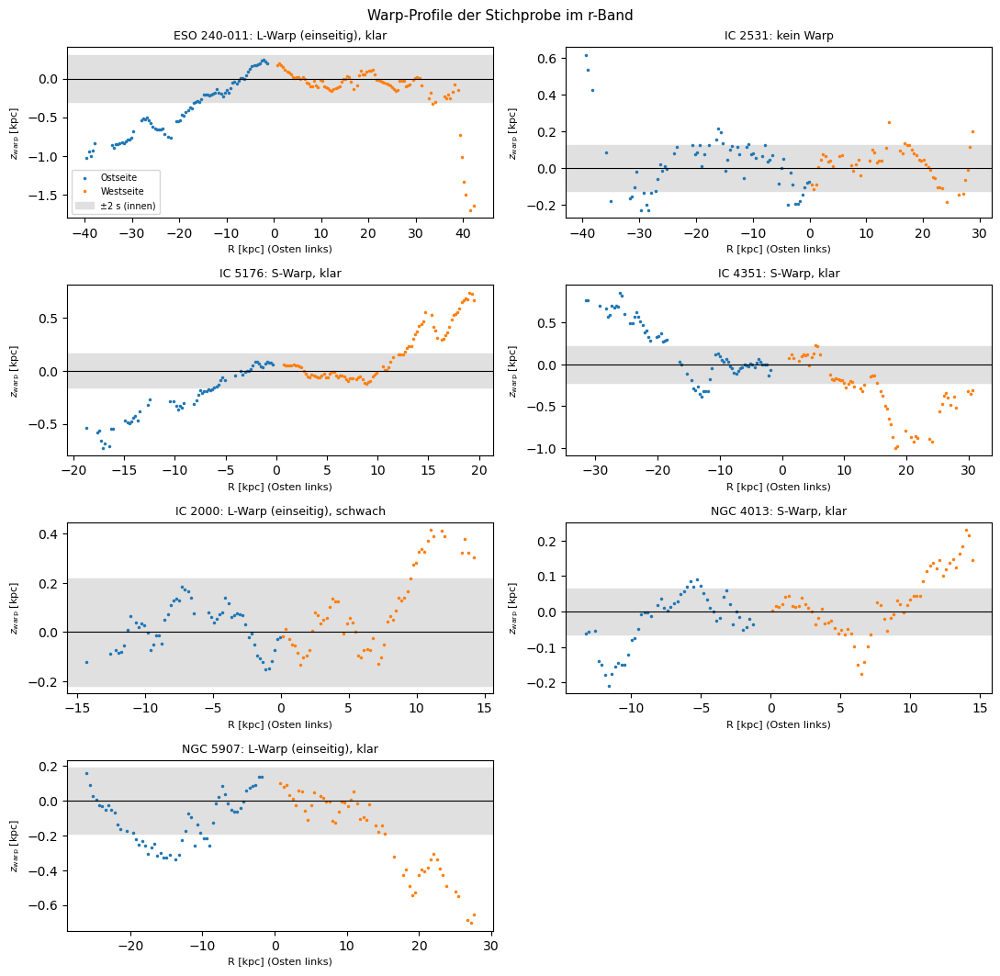

In [36]:
warps.sample_profiles()

**36. Das schwarze Loch in M 87: Daten des Event Horizon Telescope**

2019 zeigte das Event Horizon Telescope (EHT) das erste Bild eines schwarzen Lochs: einen Ring von 42 Mikrobogensekunden um den Schatten im Zentrum von M 87. Aufgenommen wurde das Bild nie. Sieben Radioteleskope auf mehreren Kontinenten messen nur einzelne Punkte der Fourier-Transformierten des Himmels, die Visibilities, und das Bild muss daraus rekonstruiert werden. Geladen werden die öffentlichen Daten von 2017: vier Nächte, zwei Frequenzbänder um 228 GHz.

51 119 Visibilities auf 21 Basislinien; die längste hat 8.33 Gλ, das gibt eine Auflösung von 25 µas. Jede Basislinie zeichnet durch die Erdrotation einen Bogen in die Fourier-Ebene, die nur dünn besetzt ist. Die Amplitude fällt mit der Basislinienlänge, hat ein Minimum bei 3.6 Gλ, steigt wieder an und fällt bei 8.3 Gλ erneut: genau das Muster eines Rings.

51,119 Visibilities, 21 Basislinien zwischen 7 Stationen
Pro Nacht: {'5. April': 12911, '6. April': 17726, '10. April': 4977, '11. April': 15505}
Längste Basislinie 8.33 Gλ -> Auflösung λ/B ≈ 25 µas
Kürzeste Basislinien: JC-SM 0.1 Mλ, AA-AP 1.9 Mλ (innerhalb eines Standorts)
Amplituden: auf kurzen Basislinien (< 0.1 Gλ) im Median 1.14 Jy, auf langen (> 1 Gλ) 0.09 Jy


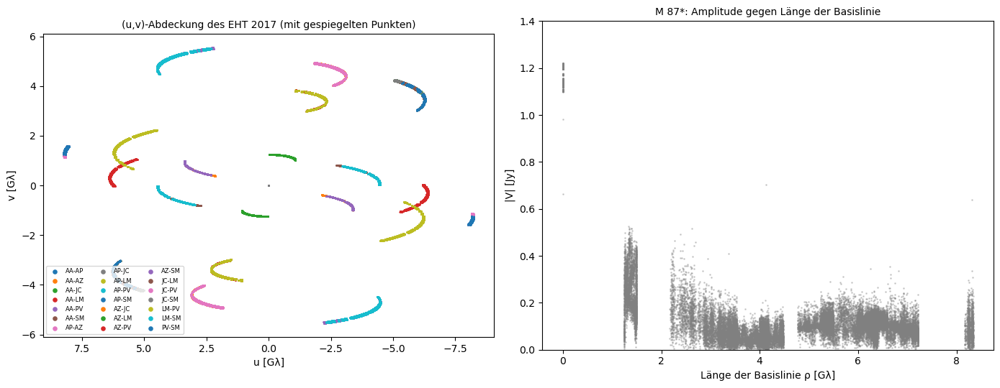

In [37]:
m87.visibilities()

**37. Phasen und Closure-Phasen**

Die Atmosphäre verschiebt die Phase an jeder Station zufällig. Addiert man die Phasen um ein Dreieck von Stationen, heben sich diese Fehler heraus; übrig bleibt die Closure-Phase, die nur von der Quelle abhängt.

Die Phase der Basislinie ALMA–SMT dreht sich in fünf Stunden um mehr als 200°, die Closure-Phase des Dreiecks bleibt zwischen +30° und +80°, im Mittel +52°, in allen vier Nächten fast gleich. Weil sie weder 0° noch 180° ist, ist das Bild nicht punktsymmetrisch, passend zur helleren Südseite des Rings.

Dreieck AA-AZ-LM am 5. April, Band lo: 509 gemeinsame Zeitpunkte
  Phase AA-AZ      Mittel  +136.4°, zirkuläre Streuung   73.6°
  Phase AZ-LM      Mittel    +8.5°, zirkuläre Streuung   35.8°
  Phase AA-LM      Mittel   +63.3°, zirkuläre Streuung   81.7°
  Closure-Phase    Mittel   +51.8°, zirkuläre Streuung   20.2°
Closure-Phase in allen Nächten: 5. April: +52° ± 20° (509), 6. April: +58° ± 18° (576), 10. April: +47° ± 31° (186), 11. April: +48° ± 20° (529)


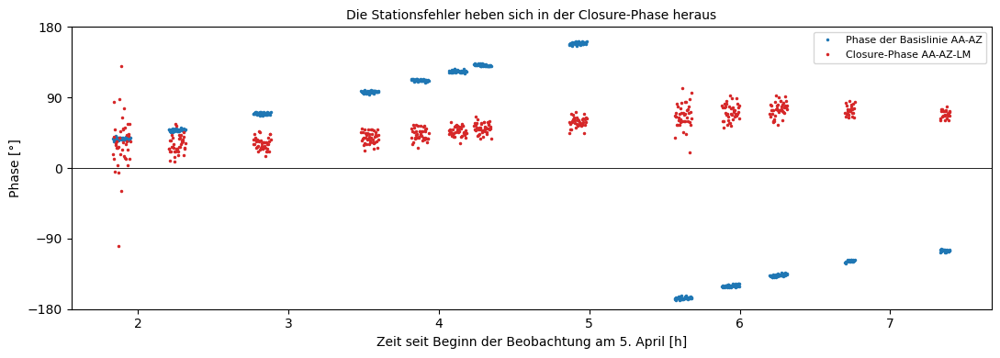

In [38]:
m87.closure_phases()

**38. Der Ringdurchmesser aus den Amplituden**

An alle Amplituden langer Basislinien wird das Modell eines dünnen Rings angepasst, mit Fluss, Durchmesser und Breite. Die erste Nullstelle legt den Durchmesser fest.

Der Ring hat 43.8 µas, die einzelnen Nächte liegen zwischen 43.5 und 44.2 µas. Der Durchmesser ist so genau, obwohl die Auflösung nur 25 µas beträgt, weil er an der Lage der Nullstelle hängt. Die Breite ist kaum bestimmt, und ein symmetrischer Ring füllt die Nullstellen nicht ganz auf: Der echte Ring ist asymmetrisch.

Ringfit an 45,623 Amplituden auf Basislinien über 1 Gλ
  Durchmesser d = 43.8 µas (formaler Fehler ± 0.02), Breite w = 3.3 µas, kompakter Fluss F = 0.30 Jy
  Erste Nullstelle der Amplitude bei 3.60 Gλ
    5. April: d = 43.5 µas, w = 0.0 µas, F = 0.29 Jy
    6. April: d = 43.6 µas, w = 0.0 µas, F = 0.28 Jy
   10. April: d = 44.2 µas, w = 5.4 µas, F = 0.31 Jy
   11. April: d = 43.9 µas, w = 10.4 µas, F = 0.42 Jy
  Streuung zwischen den Nächten: ± 0.3 µas


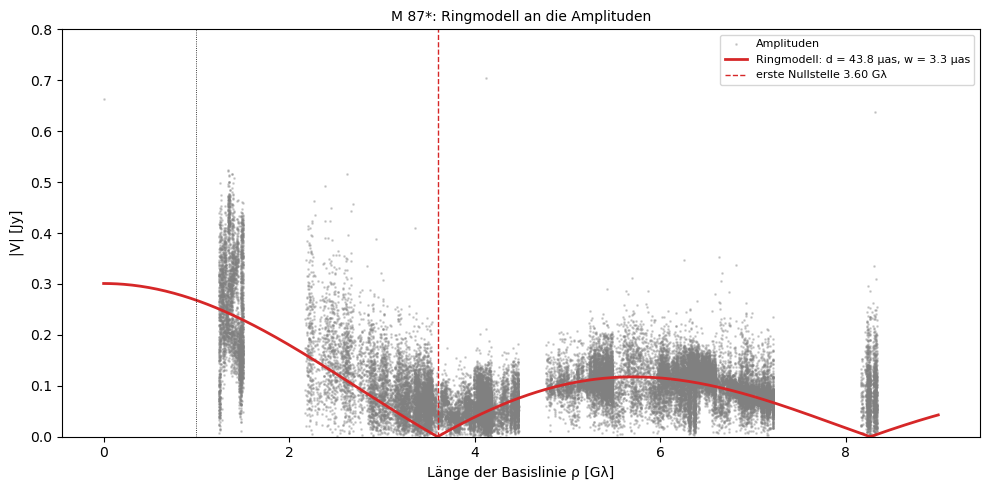

In [39]:
m87.ring_diameter()

**39. Dirty Beam und Dirty Image**

Transformiert man nur die gemessenen Fourier-Punkte zurück, erhält man das Dirty Image: das wahre Bild, gefaltet mit dem Dirty Beam, dem Bild einer Punktquelle bei dieser Abdeckung.

Der Dirty Beam hat starke Nebenkeulen, die höchste mit 65 % der Hauptkeule. Im Dirty Image eines Rings von 44 µas ist vom Ring nichts zu erkennen, nur Flecken über das ganze Feld. Ein Bild aus EHT-Daten braucht deshalb immer eine Rekonstruktion mit Annahmen über den Himmel.

1071 gemittelte (u,v)-Punkte (dazu die gespiegelten), Bild 64 x 64 Pixel zu 2.5 µas
Höchste Nebenkeule des Dirty Beam außerhalb von 25 µas: 65% der Hauptkeule


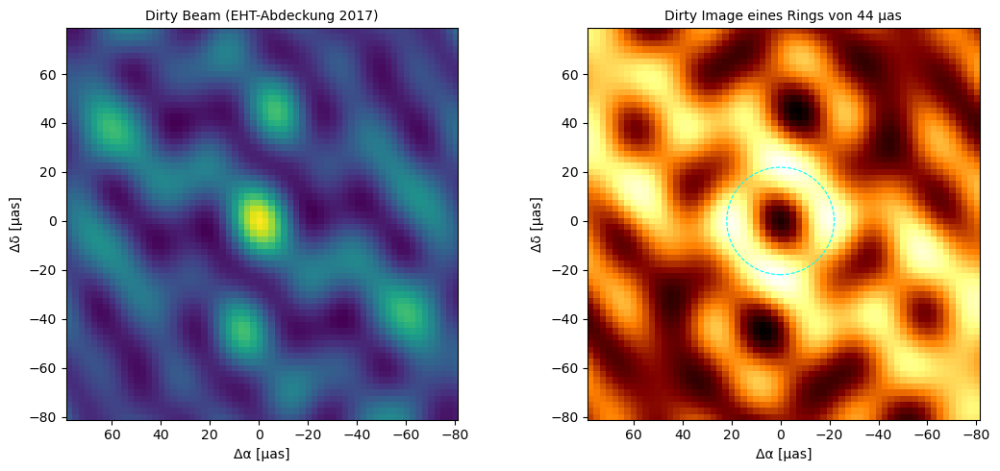

In [40]:
m87.dirty_map()

**40. CLEAN**

Der Högbom-CLEAN nimmt an, der Himmel bestehe aus wenigen Punkten: Er sucht das hellste Pixel, speichert eine Komponente, zieht den verschobenen Dirty Beam ab und wiederholt das. Angewendet auf den Ring und auf fünf Punktquellen.

Nach 87 Komponenten ist der Ring wieder ein heller Kreis, sein Zentrum aber zu 65 % gefüllt, weil der Strahl so breit ist wie der Radius des Rings. Bei den Punktquellen liegen im Dirty Image nur zwei der fünf hellsten Maxima an echten Quellen, nach CLEAN vier. Zwei Quellen, die enger stehen als die Auflösung, bleiben ein Fleck.

Ring: 87 CLEAN-Komponenten; Helligkeit in der Mitte / auf dem Ring = 0.65
Punktquellen: 43 Komponenten, Rest im Restbild 2.1% des Dirty-Maximums


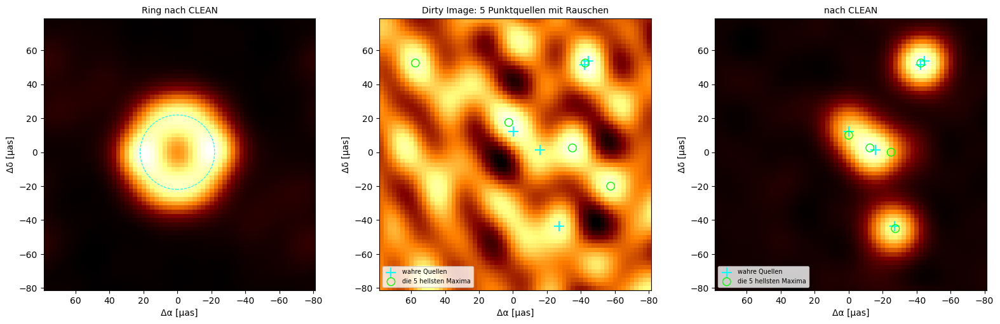

In [41]:
m87.clean()

**41. Wie viele Punktquellen findet man wieder?**

Für 1 bis 12 Quellen werden je 30 zufällige Himmel simuliert und mit und ohne CLEAN ausgewertet.

Eine Quelle findet man immer; bei zwei und drei Quellen hilft CLEAN am meisten (98 % und 94 % statt 87 % und 73 %). Bei zwölf Quellen findet man nur noch gut die Hälfte: 21 Basislinien reichen nicht für einen komplexen Himmel. Das ist das Prinzip der Rekonstruktion aus wenigen Messungen wie beim Compressed Sensing: Ein dünn besetzter Himmel lässt sich zurückgewinnen, ein komplexer nicht.

Trefferquote (Abstand unter 8 µas), 30 zufällige Himmel pro k, Rauschen 0.02 Jy pro Visibility
  k =  1:  Dirty Image 1.00 ± 0.00   |   nach CLEAN 1.00 ± 0.00
  k =  2:  Dirty Image 0.87 ± 0.04   |   nach CLEAN 0.98 ± 0.02
  k =  3:  Dirty Image 0.73 ± 0.03   |   nach CLEAN 0.94 ± 0.02
  k =  5:  Dirty Image 0.63 ± 0.03   |   nach CLEAN 0.73 ± 0.03
  k =  8:  Dirty Image 0.58 ± 0.02   |   nach CLEAN 0.65 ± 0.02
  k = 12:  Dirty Image 0.53 ± 0.02   |   nach CLEAN 0.61 ± 0.02


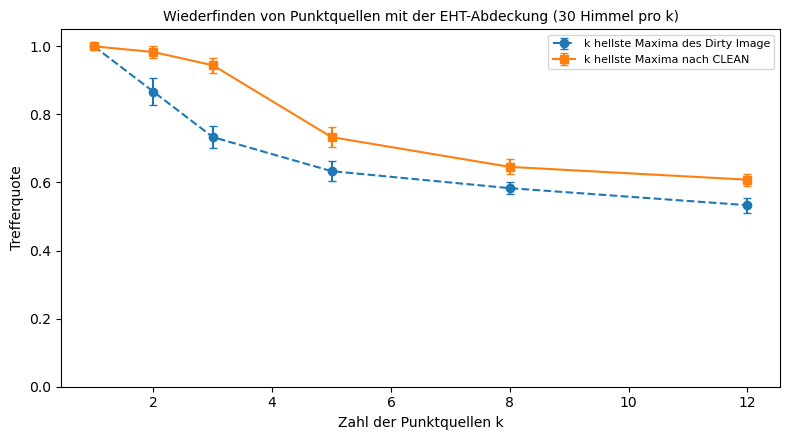

In [42]:
m87.point_sources()

**42. Durchmesser und Masse**

Aus dem veröffentlichten Ergebnis (42 µas für 6.5·10⁹ Sonnenmassen bei 16.8 Mpc) folgt das Verhältnis von Ring zu Gravitationsradius; damit wird der eigene Durchmesser zu einer Masse. Dazu die älteren Massen aus der Bewegung von Sternen und von Gas.

Der eigene Ring (43.8 µas) stimmt mit dem des EHT (42 ± 3 µas) überein und ergibt 6.8·10⁹ Sonnenmassen. Die Masse aus der Bewegung der Sterne sagt 40 µas voraus, nahe an der Messung, die aus der Gasscheibe nur 21 µas. Der Ring entscheidet den alten Widerspruch zugunsten der Sterne; das Gas wird wohl nicht nur durch Rotation getragen.

Ringdurchmesser: eigen 43.8 ± 0.3 µas (Streuung der Nächte), EHT Collaboration (2019): 42 ± 3 µas
θ_g für 6.5·10⁹ M_sun bei 16.8 Mpc: 3.82 µas; veröffentlichtes Verhältnis d / θ_g = 11.0, Schatten allein 2√27 = 10.4
Eigene Masse mit d / θ_g = 11.0: (6.79 ± 0.05)·10⁹ M_sun (nur Streuung der Nächte); wäre der Ring der Schatten selbst: 7.2·10⁹ M_sun

Vorhergesagter Ringdurchmesser für die veröffentlichten Massen (umgerechnet auf 16.8 Mpc):
  EHT Collaboration (2019), Ring   M = 6.5·10⁹ M_sun (6.5 ± 0.7)  ->  d = 42 µas
  Sterne (Gebhardt et al. 2011)    M = 6.2·10⁹ M_sun (6.6 ± 0.4 bei 17.9 Mpc)  ->  d = 40 µas
  Gas (Walsh et al. 2013)          M = 3.3·10⁹ M_sun (3.5 (+0.9/−0.3) bei 17.9 Mpc)  ->  d = 21 µas


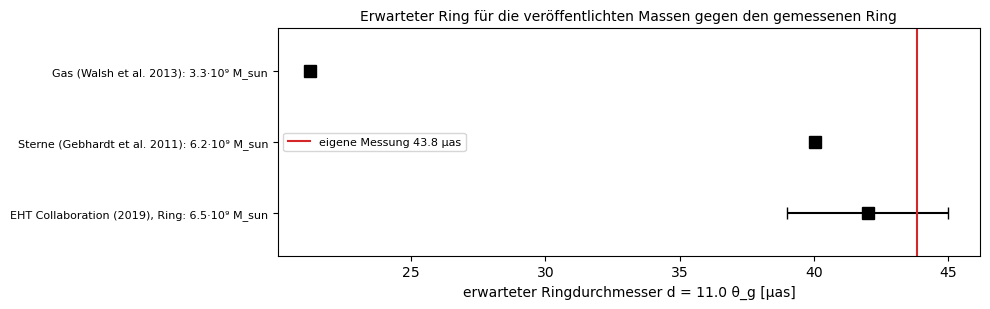

In [43]:
m87.mass()